# OCR do Livro de Registro de Leis nº 1 (1892–1894): resultados

Este caderno mostra o pipeline final aplicado às **12 páginas** transcritas (páginas 5 a 16). Ele não refaz nenhum experimento: a configuração final já foi decidida e está em `configs/final.json`. Para cada página, mostra:

1. cada operação de imagem aplicada **sobre a original**, em sequência, e a segmentação de linhas desenhada sobre a imagem;
2. cada etapa de texto (reconhecedor → reescore com dicionário e contexto → convenções → hifenização → correção) com o **WER contra o GT**;
3. o texto final ao lado do GT, com as palavras erradas marcadas;
4. o texto final **sem marcação**, como sai do pipeline, ao lado do GT;
5. o recorte de cada linha ao lado do texto lido dela.

O processo completo está em `PROCESSO.md`.

## Sem vazamento de dados

- **Nenhuma destas 12 páginas entrou no treino de pesos.**
  - O reconhecedor é o PP-OCRv6 medium ajustado com **78 outras páginas do mesmo livro** (fotos do acervo da Fundação Pró-Memória de São Carlos, uso autorizado).
  - Os rótulos dessas páginas são **transcrições diplomáticas feitas pelo Gemini** (LLM), alinhadas às linhas. Nenhuma transcrição humana do livro foi usada.
  - O pipeline não usa LLM para ler: só segmentador, reconhecedor, dicionário e modelo de contexto.
- **Dicionário e contexto** vêm de textos da época:
  - livros do Projeto Gutenberg de autores nascidos entre 1790 e 1875;
  - leis de São Paulo de 1889 a 1910, sem os atos que citam São Carlos;
  - no modelo de contexto, também o texto das 78 páginas de treino. Nenhuma das 12 páginas avaliadas entra nele.
- **Os parâmetros foram ajustados só nas 9 páginas de ajuste** (5, 6, 8, 9, 11, 13, 14, 15, 16). Para escolher o reconhecedor, também foram usadas 10 páginas novas do livro, nunca usadas em treino, com a transcrição do Gemini como referência.
- **As páginas 7, 10 e 12 ficaram reservadas.** Não participaram de nenhuma escolha. Foram avaliadas uma vez para a v4 e uma segunda vez para a final, já congelada. O número delas é a estimativa honesta.

## Resultado

WER normalizado (minúsculas, sem pontuação), somando as edições do corpus. Quanto menor, melhor.

| configuração | ajuste (9) | **reservadas (7, 10, 12)** | todas (12) |
|---|---:|---:|---:|
| modelo como publicado, imagem crua, sem pós-processamento | 63,15 | 64,57 | 63,52 |
| primeira entrega (v1: léxico moderno, reescore CTC) | 46,95 | 48,66 | 47,40 |
| dicionário de época + contexto (v3) | 36,00 | 36,85 | 36,23 |
| pipeline completo com o modelo publicado (v4, medium) | 29,63 | 28,50 | 29,33 |
| reconhecedor auto-treinado com rótulos do próprio pipeline (v4) | 24,77 | 22,05 | 24,05 |
| **final**: reconhecedor ajustado com transcrições do Gemini (`configs/final.json`) | 19,98 | **18,43** | **19,57** |

A meta do projeto era WER normalizado ≤ 50%. Nas reservadas, o CER normalizado cai de 21,71% para **4,13%**.

## O que foi testado e o que ficou

### Arquitetura

Três fluxos de imagem compartilham a mesma geometria:

```
original → geometria (ampliação, deskew) = base (define as coordenadas)
base → operações da segmentação   → segmentador neural blla (Kraken) → linhas (polígonos)
base → imagem do reconhecimento   → PP-OCRv6 ajustado ao livro (Kraken) → texto → pós-processamento
```

As operações fotométricas não movem pixels, então os polígonos achados numa imagem valem na outra. Isso permite **segmentar numa imagem e reconhecer em outra**. O primeiro ganho veio daí: binarizar ajudava a segmentação, mas o reconhecedor perdia 9,6 pontos lendo pixels binarizados.

### Progressão (WER norm. %)

| versão | o que entrou | ajuste | reservadas |
|---|---|---:|---:|
| crua | modelo publicado, sem tratamento | 63,15 | 64,57 |
| v1 | imagens separadas, convenções, hifenização, léxico pt-BR, reescore CTC, busca gulosa | 46,95 | 48,66 |
| v3 | dicionário de época (grafia anterior a 1911) e modelo de contexto (n-gramas) | 36,00 | 36,85 |
| v4 | ordinais, palavras curtas, n-best, corpus legislativo da época; tudo redecidido | 29,63 | 28,50 |
| v4 | reconhecedor auto-treinado nas outras 91 páginas + busca final | 24,77 | 22,05 |
| **final (v5)** | reconhecedor ajustado com transcrições do Gemini de 78 páginas, texto do livro no contexto, deskew | **19,98** | **18,43** |

### Como a configuração é escolhida: busca gulosa condicional

Testar cada mudança isolada sobre a crua e somar as que ganham não funciona, porque os efeitos interagem. A busca roda só nas 9 páginas de ajuste:

- As etapas são decididas em ordem, sempre **sobre o melhor conjunto atual**.
- Em cada etapa, cada candidato é testado sozinho. O melhor entra só se superar a referência.
- Depois, **todos os outros** candidatos da etapa são testados por cima do vencedor, inclusive os que pioraram sozinhos. Cada um fica só se melhorar.
- Um passe para trás remove qualquer escolha cuja retirada não piore.
- Os passes se repetem até nada mudar. Nenhuma decisão é definitiva.

Com ~1.000 configurações sorteadas no mesmo espaço, uma busca aleatória chegou a 43,62. A gulosa chegou a 36,00.

### O reconhecedor: auto-treino com as outras páginas do livro

Uma análise dos erros mostrou que o teto estava no reconhecedor. Muitas palavras eram lidas tão longe da certa que nenhum dicionário as recuperava. Ajustar o modelo com o GT das páginas de ajuste valia ~18 pontos, mas usaria transcrições do conjunto avaliado.

A solução foi usar as **outras 91 páginas do livro**, que não têm transcrição:

1. o pipeline lê essas páginas;
2. as linhas lidas com confiança viram rótulos;
3. o modelo é ajustado com elas;
4. o modelo novo gera rótulos melhores, e o ciclo se repete.

O filtro de confiança foi calibrado nas páginas de ajuste, e as reservadas não participaram.

| rodada | linhas de treino | reconhecedor sozinho | pipeline |
|---|---:|---:|---:|
| medium publicado | — | 61,17 | 29,91 |
| 1 | 1.339 | 43,45 | 28,67 |
| 2 | 1.577 | 42,10 | 27,37 |
| **3 (final)** | 1.840 | 40,18 | **26,07** |
| 4 | 1.931 | 39,05 | 26,69 |

Valores em WER, nas páginas de ajuste. A 4ª rodada piorou o pipeline, e o ciclo parou ali.

### O reconhecedor final: transcrições do Gemini

O auto-treino parou porque os rótulos vinham do próprio pipeline. A alternativa foi pedir ao Gemini transcrições diplomáticas das outras páginas: grafia original, como um historiador. Contra o GT humano das 12 páginas (só medição), o Gemini tem WER 17,8 e CER 4,5.

- 78 páginas de treino, 10 de teste sorteadas entre as novas, as 12 avaliadas em quarentena.
- A transcrição é alinhada às linhas do segmentador. Linhas a mais de 0,4 da leitura do modelo ficam de fora.
- Treinar só com transcrições é melhor do que misturar com pseudo-rótulos.
- O texto dessas páginas no modelo de contexto ensina as fórmulas do livro ("Multa de dez mil reis"): −1,35 ponto sozinho.

| reconhecedor | ajuste | teste (10 páginas novas, ref. Gemini) |
|---|---:|---:|
| st_g2gem (48 transcrições, a partir do st_v3) | 19,47 | 4,87 |
| **st_g3m** (78 transcrições, a partir do medium) | 19,98 | **3,45** |

No ajuste, a diferença é de ~9 palavras, ruído. Em páginas novas, o st_g3m ganha 1,4 ponto, e ele nunca viu nenhuma imagem avaliada. Uma nova busca gulosa ganhou no ajuste mas piorou no teste (sobreajuste). Dela, só ficou o deskew, que endireita a página e leva a página 5 de 42 para 33.

**Quanto cada escolha vale** (WER nas páginas de ajuste ao retirar só ela, na busca da v4):

| retirar | custo |
|---|---:|
| dicionário de época | +15,58 |
| modelo de contexto | +6,49 |
| reconhecedor auto-treinado (voltar ao publicado) | +4,9 |
| permitir trocar também palavras que estão no dicionário | +3,33 |
| ampliação ×2 | +2,43 |
| candidatas para palavras curtas (de/da/do…) | +1,52 |
| feixe como fonte de candidatas extras | +0,68 |
| padding 24 | +0,62 |
| trigrama | +0,51 |
| as demais | < 0,4 cada |

O custo do reconhecedor compara a busca final com a do medium (29,63 contra 24,77). As outras linhas são retiradas uma a uma.

### Outros reconhecedores, como publicados

| reconhecedor | resultado |
|---|---|
| **PP-OCRv6 medium** | **CER norm. 22,0** (páginas 6, 8, 13) |
| PP-OCRv6 small | ≈ 4 pontos de WER pior em todas as páginas |
| TraPrInq (Inquisição portuguesa, séc. XVI–XIX) | CER norm. 38,8 |
| McCATMuS (multilíngue, séc. XVI–XXI) | CER norm. 51,2 |

Não existe modelo público para manuscrito brasileiro do século XIX. O ajuste com as transcrições adapta o melhor deles a esta mão.

### Limites

- Só 3 páginas reservadas, ~640 palavras: 1 ponto de WER ≈ 6 palavras.
- As reservadas já tinham sido olhadas em campanhas exploratórias anteriores do projeto, antes deste pipeline. Nenhuma escolha deste pipeline foi feita com elas, mas a separação não é perfeitamente cega.
- Os rótulos do reconhecedor vêm de um LLM, com erros (CER ~4,5). O teste de 10 páginas usa a mesma fonte como referência.
- O reconhecedor está adaptado a este livro. Em outro livro, o ponto de partida é o pipeline com o modelo publicado, ou um novo ajuste com páginas transcritas daquele livro.
- O GT não foi verificado e tem erros prováveis (p. ex. `com causa` contra `sem causa`). Também mistura grafia original e modernizada. Parte do erro restante é da referência.
- A página 5 é outro recorte (521×543 px, 45 palavras) e continua a pior (35,6%).

## Configuração final (`configs/final.json`)

| etapa | valor |
|---|---|
| geometria | ampliação ×2 → deskew |
| imagem de segmentação | contraste ×1,8 → remoção da pauta |
| segmentador | blla (padrão do Kraken), sem filtro de linhas |
| imagem de reconhecimento | a própria base, sem tratamento |
| reconhecedor | **st_g3m**: PP-OCRv6 medium (Zenodo 10.5281/zenodo.21788410) ajustado com as transcrições do Gemini de 78 outras páginas do livro, padding 24 |
| reescore CTC | α = 16, 30 candidatas por palavra, buscadas a partir das 5 leituras mais prováveis |
| contexto | trigramas de palavras do corpus de época + legislativo + texto das 78 páginas de treino, β = 1; feixe de 64 como fonte extra de candidatas |
| texto | convenções, ordinais e hifenização |
| dicionário | só o de época + legislativo; razão de edição 0,5; palavras com ≥ 4 letras; 60 palavras curtas |

## O que cada etapa faz (e por que nenhuma usa a resposta)

**Imagem**

| etapa | o que faz |
|---|---|
| ampliação ×2 | aumenta a imagem; o traço fino fica com mais pixels |
| contraste ×1,8 | realça a tinta, só na imagem usada para achar as linhas |
| remoção da pauta | apaga as linhas horizontais do papel, só na imagem de segmentação, para elas não virarem "linhas de texto" |

**Texto**

| etapa | o que faz | usa o GT? |
|---|---|---|
| **reconhecedor (guloso)** | O modelo dá, para cada fatia da linha, a probabilidade de cada caractere. "Guloso" é pegar sempre o mais provável e juntar: é a saída crua do modelo. | não |
| **reescore com dicionário e contexto** | Para cada palavra lida, busca palavras parecidas no dicionário de época, também a partir das outras leituras prováveis do modelo. Cada candidata recebe duas notas: o quanto o próprio modelo a acha compatível com a imagem e o quanto ela é provável entre as vizinhas, pelos n-gramas do corpus da época. Escolhe a melhor sequência da linha inteira. | não |
| **convenções e ordinais** | Regras fixas de notação: o modelo escreve `n^o`, `⁋` e `2o`, a transcrição usa `nº`, `§` e `2º`. | não usa o texto; ver a primeira ressalva |
| **hifenização** | Se a linha termina em `-`, junta com a primeira palavra da linha seguinte (`Camar-` + `go` → `Camargo`). | não |
| **correção léxica** | Troca palavras fora do dicionário pela mais próxima, se a diferença for pequena (até metade das letras). | não |

**Ressalvas**

1. **Regra das convenções.** Ela existe porque foi observado como o GT representa esses símbolos. Não é a resposta de nenhuma página, e sim o padrão de notação da transcrição (como saber que o gabarito escreve § e não ⁋). Vale cerca de 0,5 ponto.
2. **Parâmetros.** Foram escolhidos olhando o WER das 9 páginas de ajuste. Isso inclui o quanto corrigir, os pesos do reescore e do contexto, o tratamento de imagem e o limiar de alinhamento dos rótulos. É ajuste de limiares, não treino com o GT.

   A prova de que não vale só para essas páginas: nas 3 reservadas, que não participaram de nada, o WER cai de 64,57 para 18,43, ganho até maior que nas páginas de ajuste (63,15 para 19,98).
3. **Corpus legislativo.** Das 2.258 sequências de 8 palavras do GT, 11 aparecem no corpus de leis da época. Todas são fórmulas jurídicas (_revogam-se as disposições em contrario_). É conhecimento do gênero, o mesmo que um transcritor da época teria.
4. **Generalização.**
   - O pós-processamento (dicionário de época, contexto, hifenização) vale para outros documentos da mesma época.
   - O reconhecedor foi adaptado a este escrivão. Em outro livro, pode ser preciso repetir o ajuste com páginas transcritas dele.

## Preparação

In [1]:
# Ambiente. No Colab: obtém o código, entra na pasta e instala as dependências (o torch do Colab é mantido).
# Localmente, abra o caderno de dentro da pasta entrega_ocr; esta célula não faz nada.
import os
import subprocess
import sys
from pathlib import Path

ORIGEM = 'github'  # 'github': clona o repositório público | 'drive': usa a pasta Meu Drive/entrega_ocr
REPOSITORIO = 'https://github.com/fabiolobato/hackathon_ocr_historico.git'
RAMO = 'feat/random_search_period_lexicon'

if 'google.colab' in sys.modules:
    if ORIGEM == 'drive':
        from google.colab import drive
        drive.mount('/content/drive')
        pasta = Path('/content/drive/MyDrive/entrega_ocr')  # ajuste se a pasta estiver em outro lugar
    else:
        clone = Path('/content/hackathon_ocr_historico')
        if not clone.is_dir():
            subprocess.run(['git', 'clone', '--depth', '1', '-b', RAMO, REPOSITORIO, str(clone)], check=True)
        pasta = clone / 'entrega_ocr'
    os.chdir(pasta)
    subprocess.run([sys.executable, 'setup_pipeline.py'], check=True)  # instala o Kraken, baixa e confere modelo e léxico
print('pasta de trabalho:', Path.cwd())

pasta de trabalho: /Users/felipe_azambuja/hackathon_ocr_historico/entrega_ocr


In [2]:
import logging
import warnings

import torch
from IPython.display import HTML, display

from ocr_pipeline.config import load_config
from ocr_pipeline.data import discover, split
from ocr_pipeline.engine import Engine
from ocr_pipeline.presentation import page_html, stage_corpus, style, summary_html
from ocr_pipeline.visualize import bar_svg

logging.basicConfig(level=logging.WARNING)
warnings.filterwarnings('ignore', module='coremltools')  # aviso inofensivo do Kraken no macOS
GT = Path('ground_truth') if Path('ground_truth').is_dir() else Path('test_kraken/ground_truth')  # pasta de entrega ou repositório
PAGINAS = discover(Path('imagens'), GT)
AJUSTE, RESERVADAS = split(PAGINAS)  # semente 42: reservadas = 7, 10, 12
RESERVADAS_N = {p.number for p in RESERVADAS}
NOME = 'final'
CONFIG = load_config(Path('configs/final.json'))
DISPOSITIVO = 'cuda:0' if torch.cuda.is_available() else 'cpu'
ENGINE = Engine(Path('cache'), DISPOSITIVO, seed=42)
RESULTADOS = {NOME: {}}


def mostrar_html(corpo: str) -> None:
    display(HTML(f'{style()}<div class="ocr-body">{corpo}</div>'))


def mostrar(numero: int) -> None:
    """Roda a configuração final na página e mostra imagens, etapas de texto e WER."""
    pagina = next(p for p in PAGINAS if p.number == numero)
    tipo = 'reservada' if numero in RESERVADAS_N else 'ajuste'
    corpo, etapas = page_html(ENGINE, pagina, CONFIG, AJUSTE, f'página {numero} ({tipo})')
    RESULTADOS[NOME][numero] = etapas
    mostrar_html(corpo)


print('páginas:', [p.number for p in PAGINAS])
print('ajuste:', [p.number for p in AJUSTE], '| reservadas:', sorted(RESERVADAS_N))
print('dispositivo:', DISPOSITIVO)

páginas: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
ajuste: [5, 6, 8, 9, 11, 13, 14, 15, 16] | reservadas: [7, 10, 12]
dispositivo: cpu


## Página por página

Cada célula roda a configuração final em uma página. A primeira execução leva de 20 a 60 s por página em CPU; os resultados ficam em `cache/` e as execuções seguintes são imediatas.

Como ler cada cartão:

- **geometria / imagem de segmentação / imagem de reconhecimento**: cada imagem é a anterior com mais uma operação, e a legenda dá o valor do parâmetro. A última imagem da segmentação mostra as linhas encontradas (polígono colorido + linha de base, numeradas na ordem de leitura).
- **texto: cada etapa**: WER e CER depois de cada operação de texto, e Δ em relação à etapa anterior.
- **texto final contra o GT**: <span style="text-decoration:line-through">riscado</span> = palavra errada, em verde = o que o GT diz. Ao lado está o GT.
- **texto final previsto, sem marcações**: a saída do pipeline como ela é, ao lado do GT, para ler o resultado sem as correções sobrepostas.
- **linha a linha** (expandir): recorte da imagem de reconhecimento ↔ texto lido ↔ mudanças do reescore CTC.

### Página 5 (ajuste)


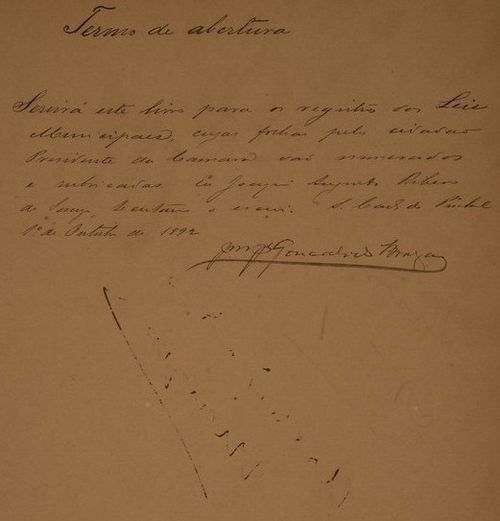
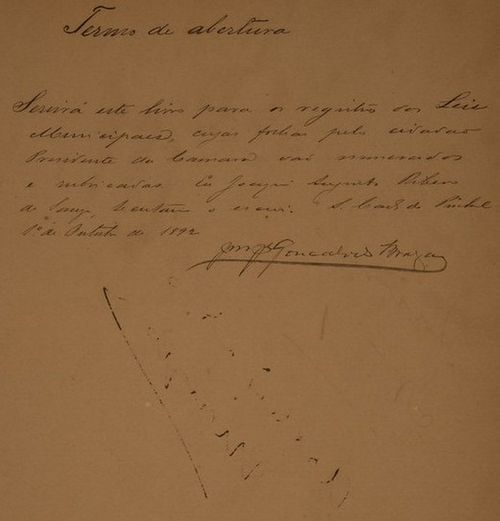
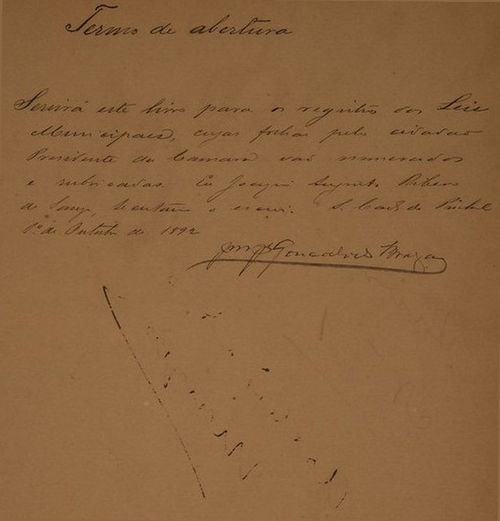
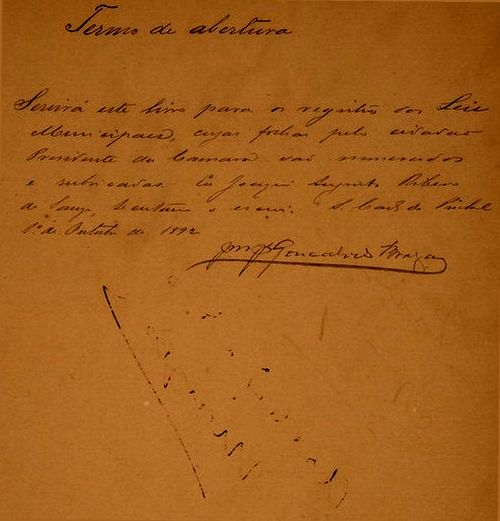
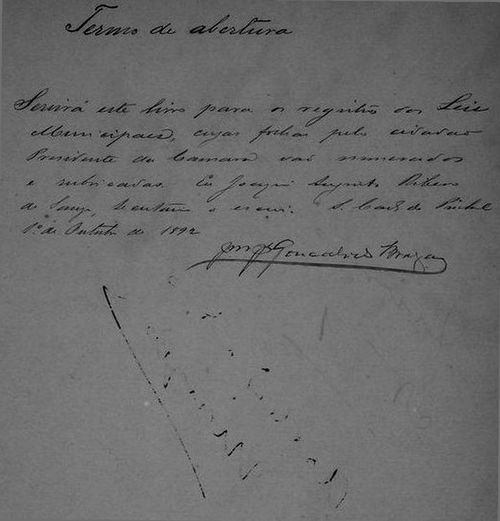
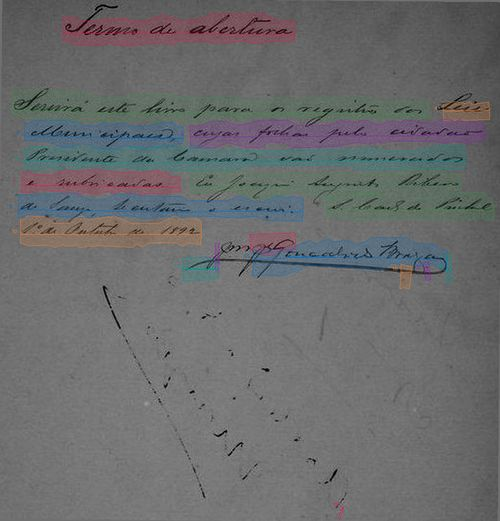
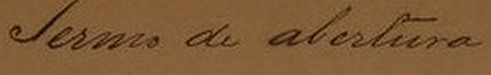
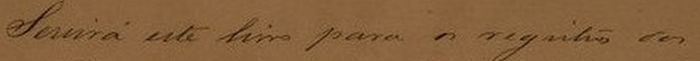
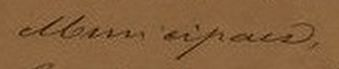
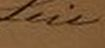
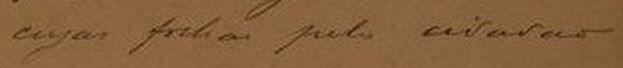
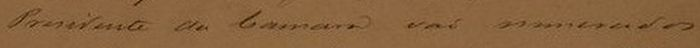
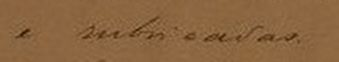
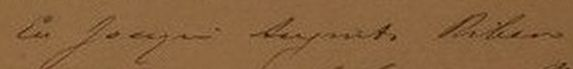
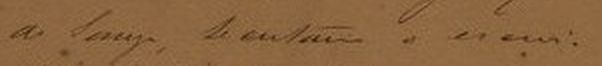
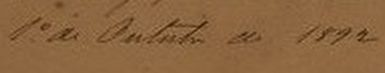
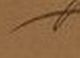
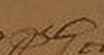
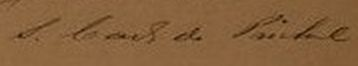
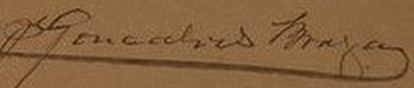
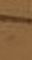

In [3]:
mostrar(5)

### Página 6 (ajuste)


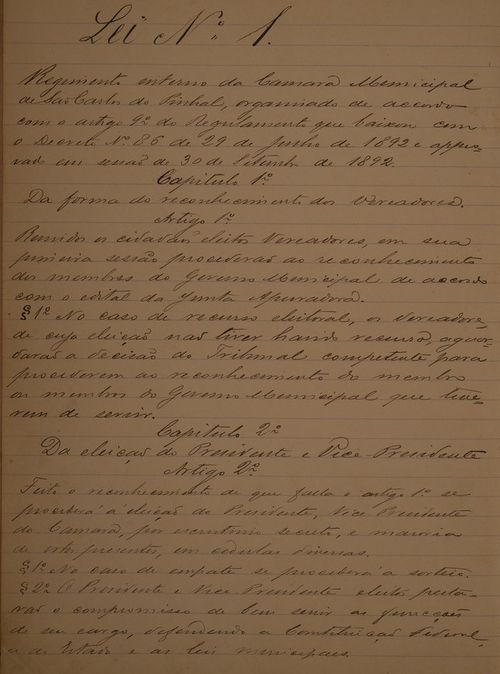
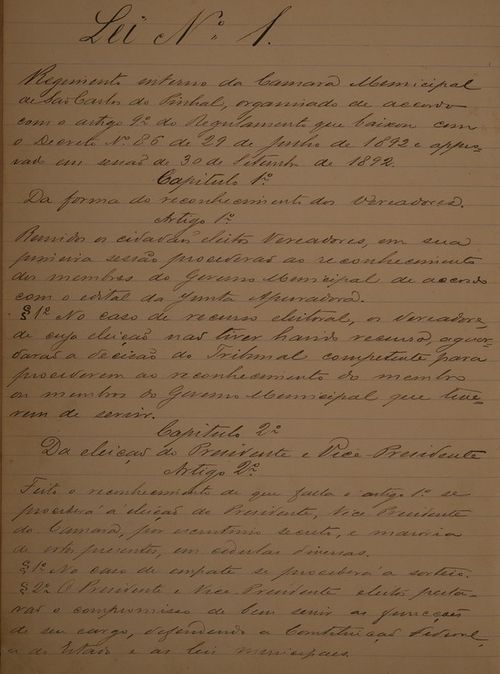
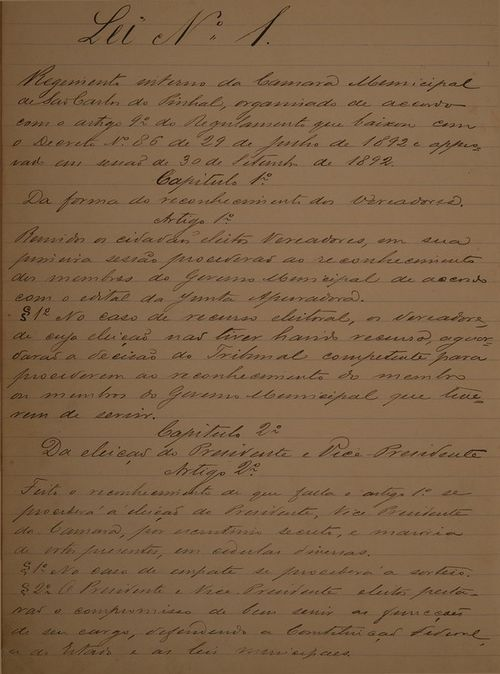
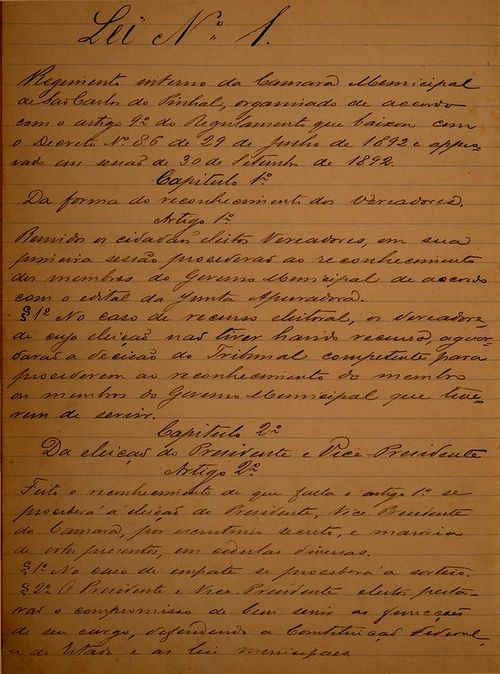
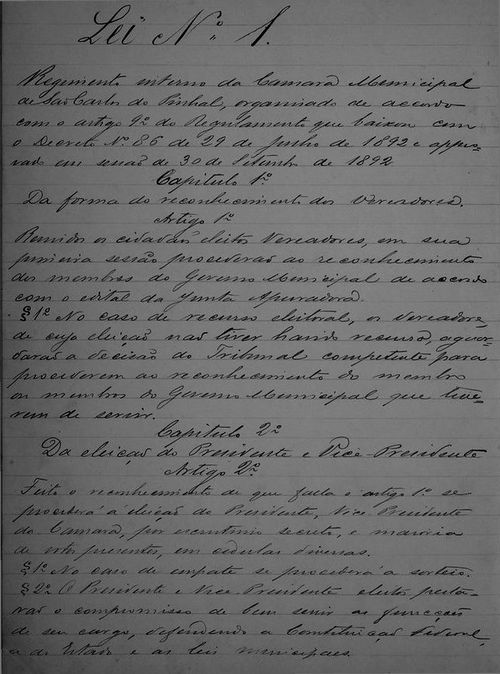
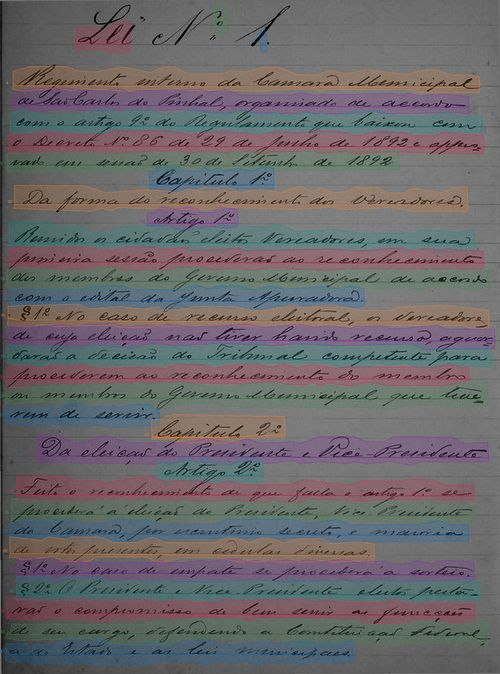
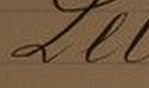
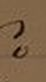
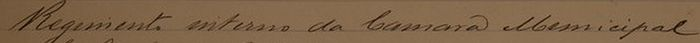
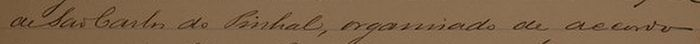
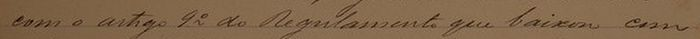
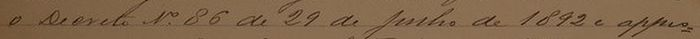
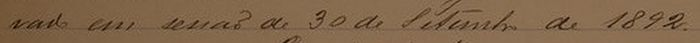
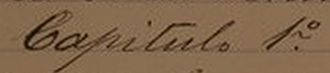
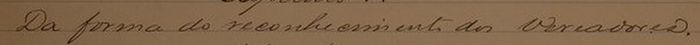
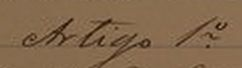
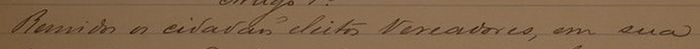
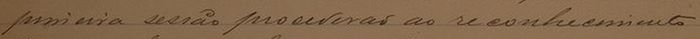
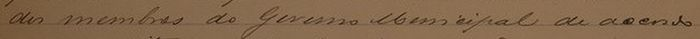
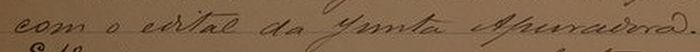
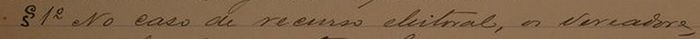
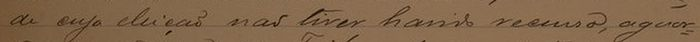
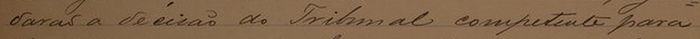
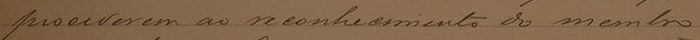
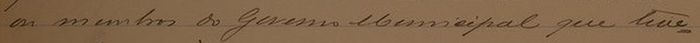
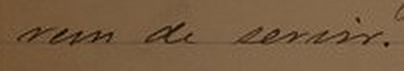
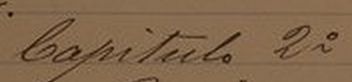
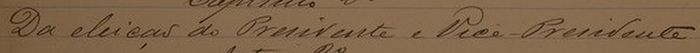
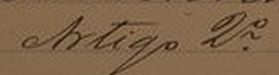
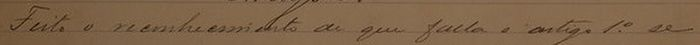
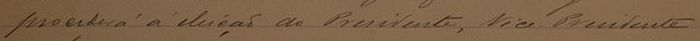
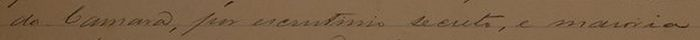
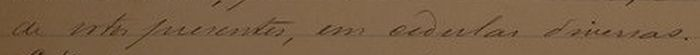
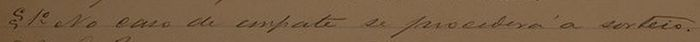
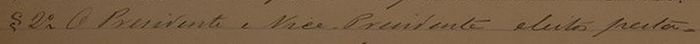
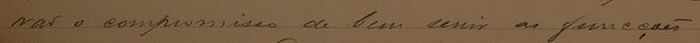
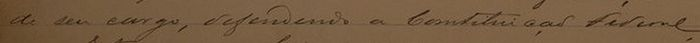
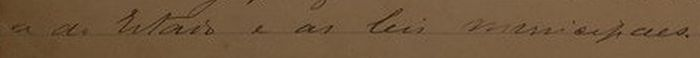

In [4]:
mostrar(6)

### Página 7 (reservada)


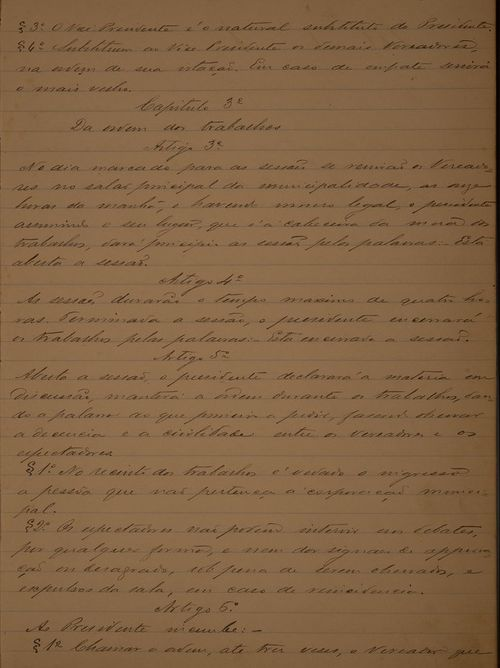
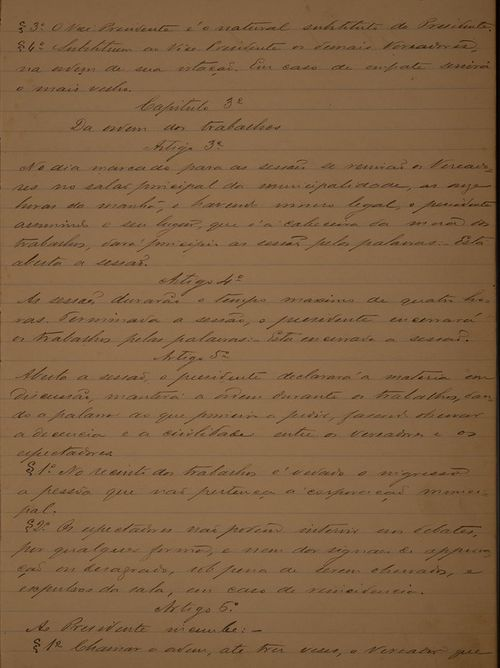
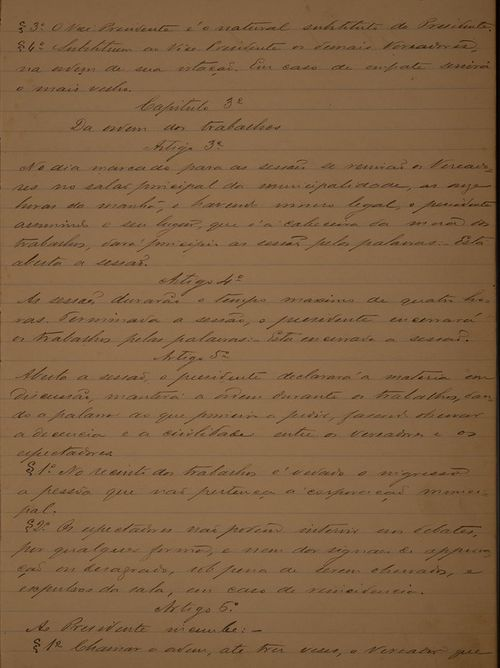
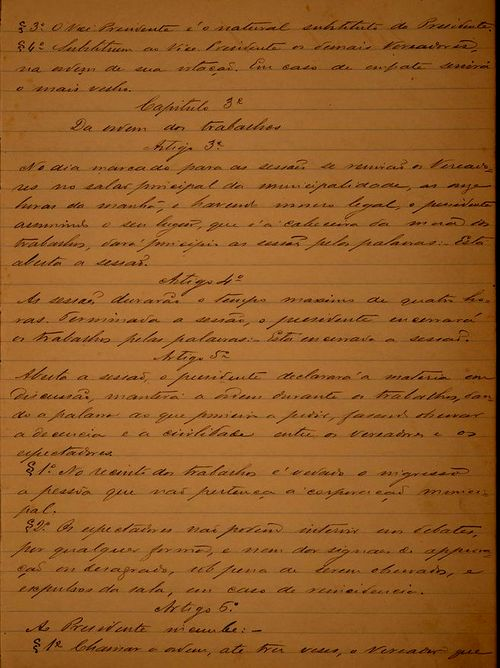
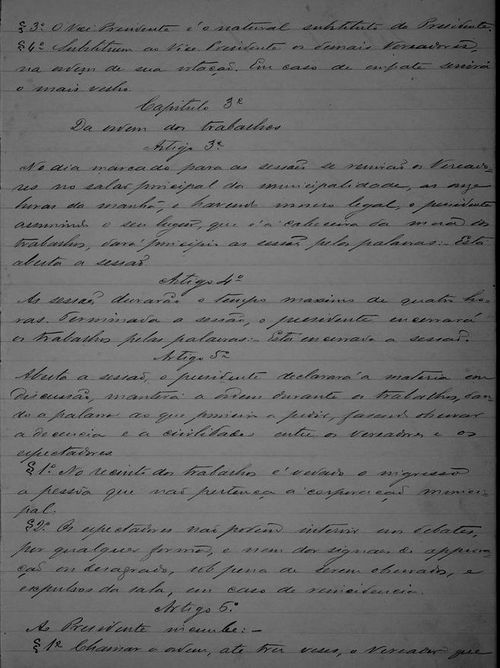
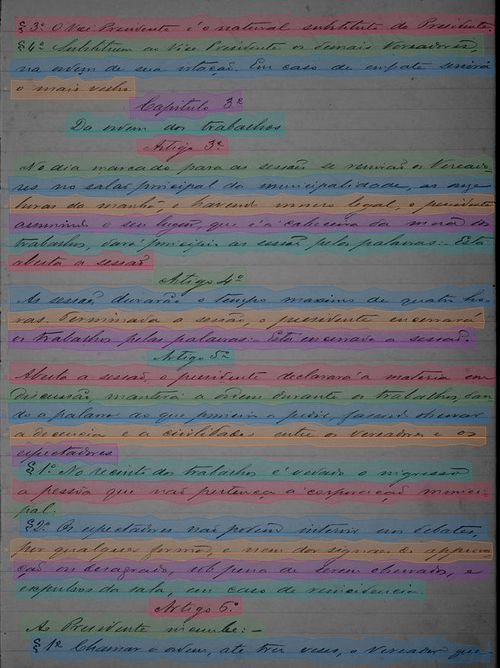
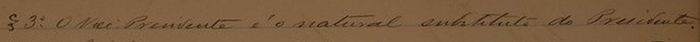
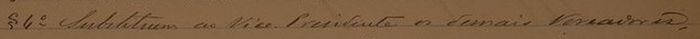
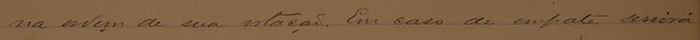
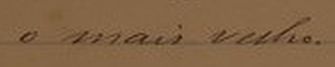
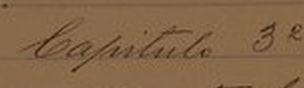
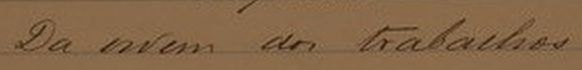
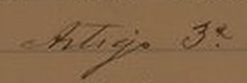
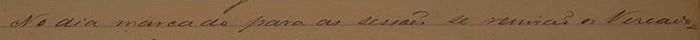
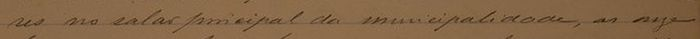
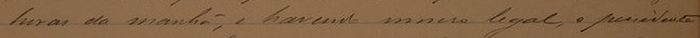
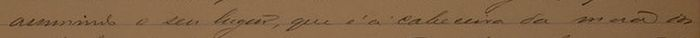
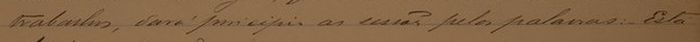
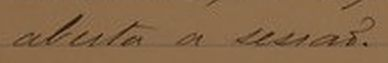
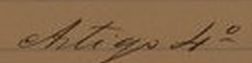
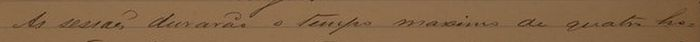
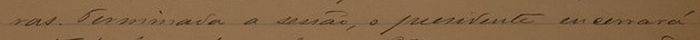
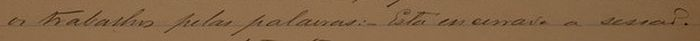
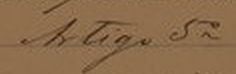
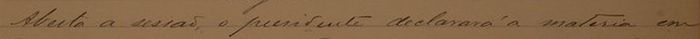
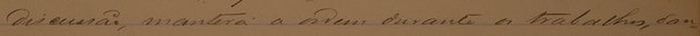
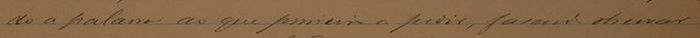
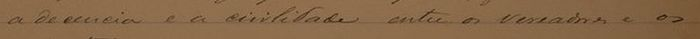
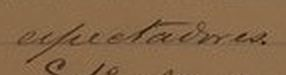
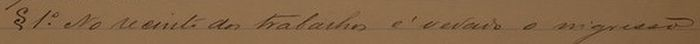
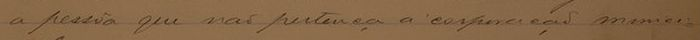
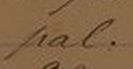
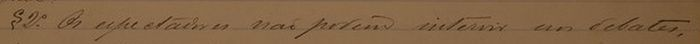
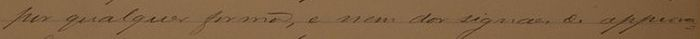
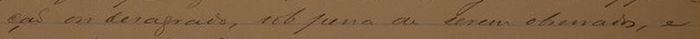
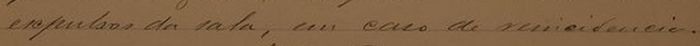
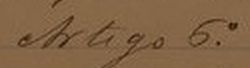
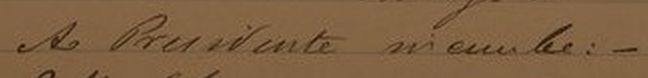
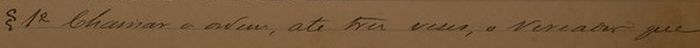

In [5]:
mostrar(7)

### Página 8 (ajuste)


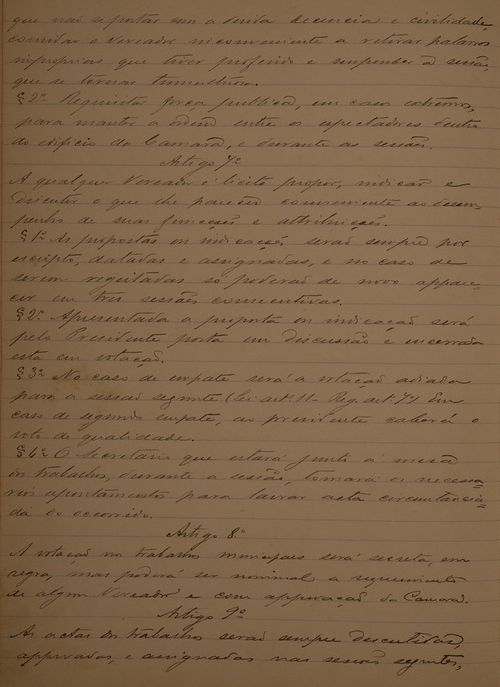
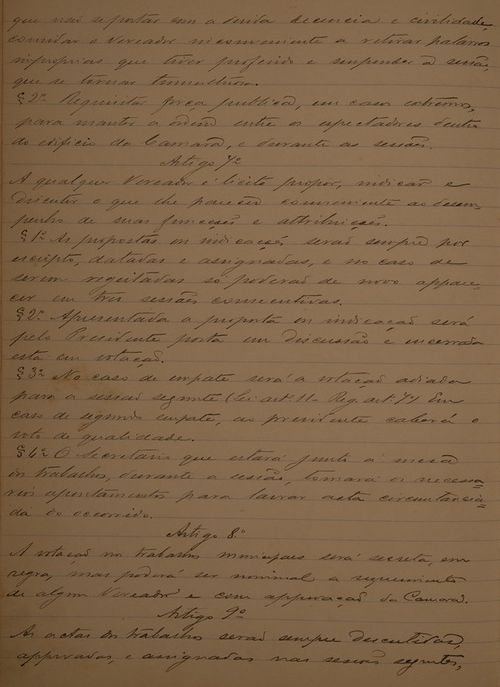
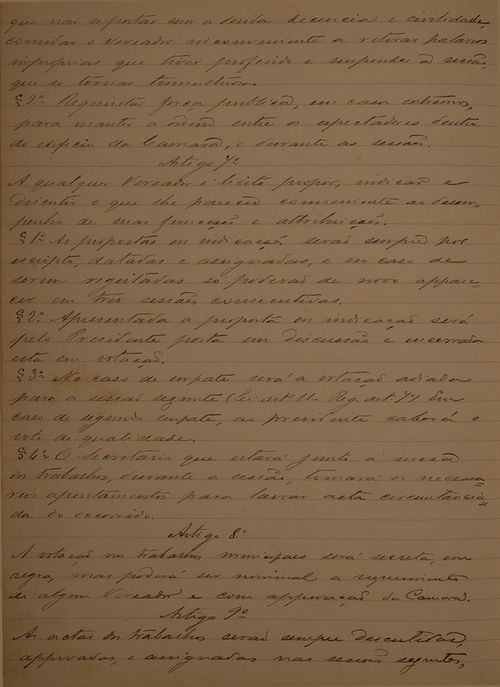
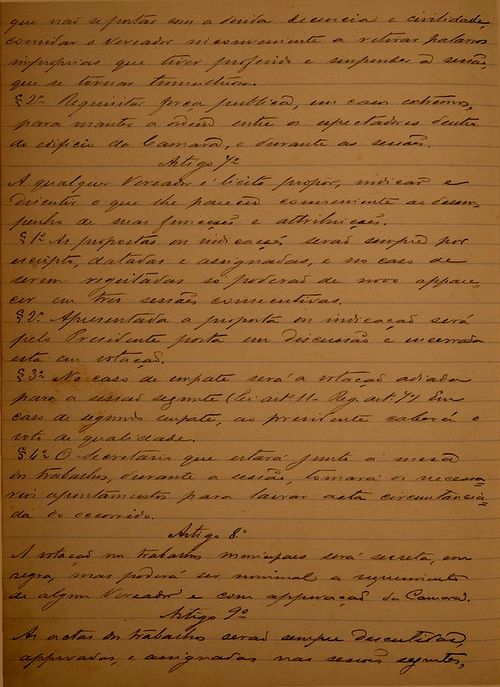
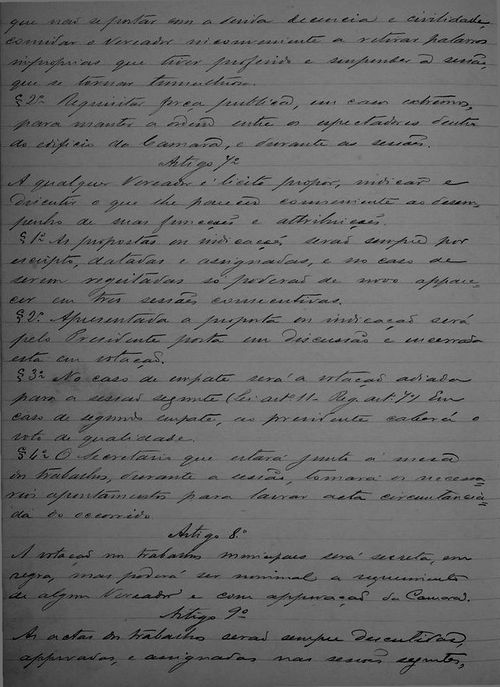
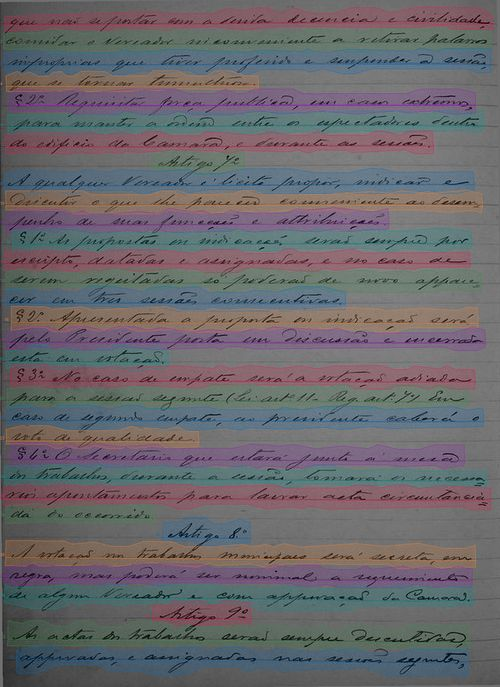
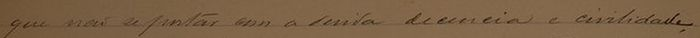
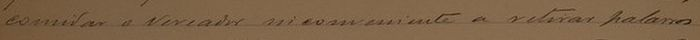
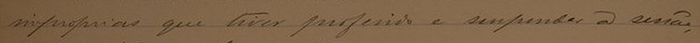
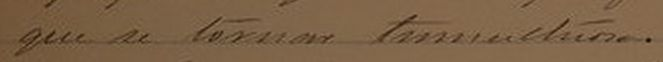
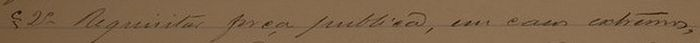
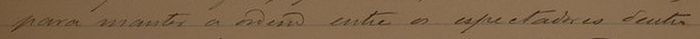
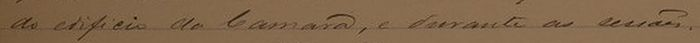
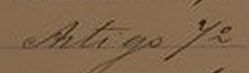
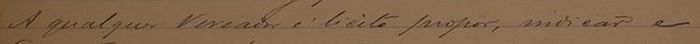
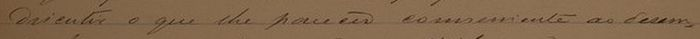
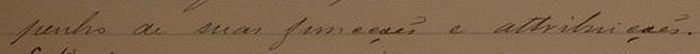
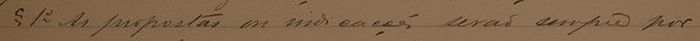
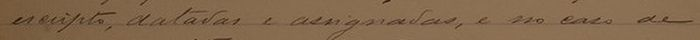
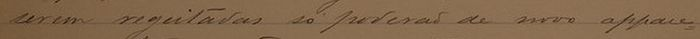
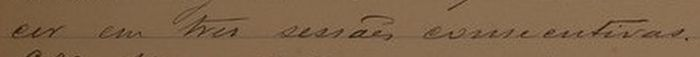
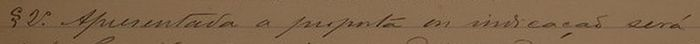
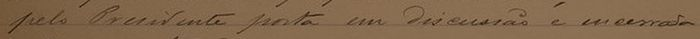
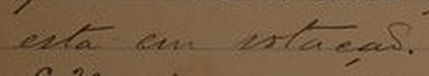
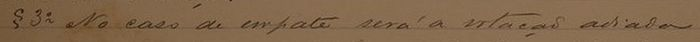
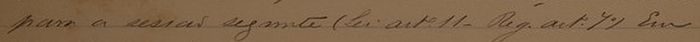
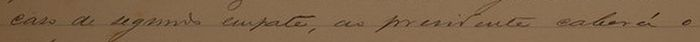
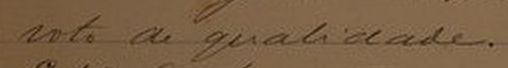
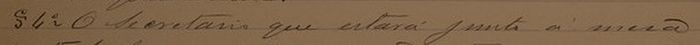
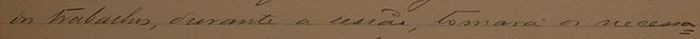
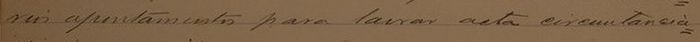
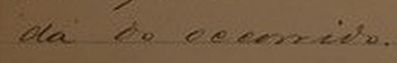
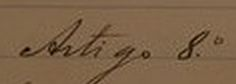
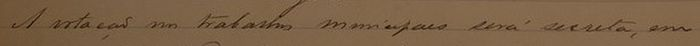
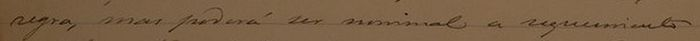
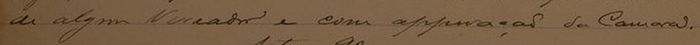
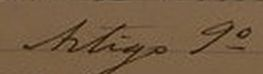
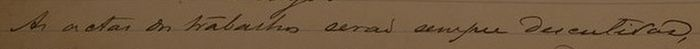
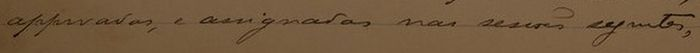

In [6]:
mostrar(8)

### Página 9 (ajuste)


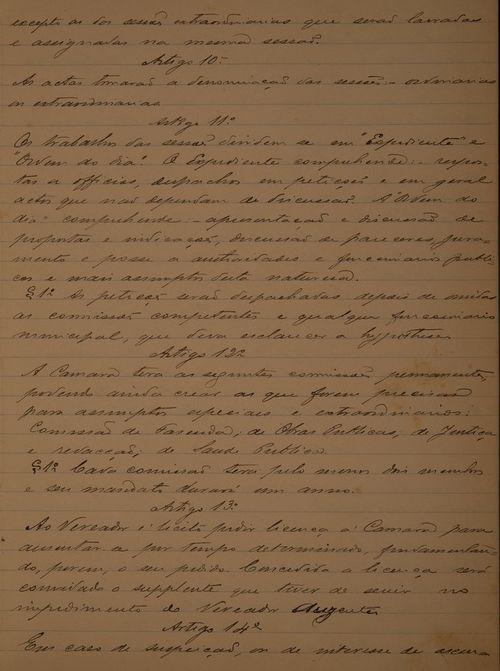
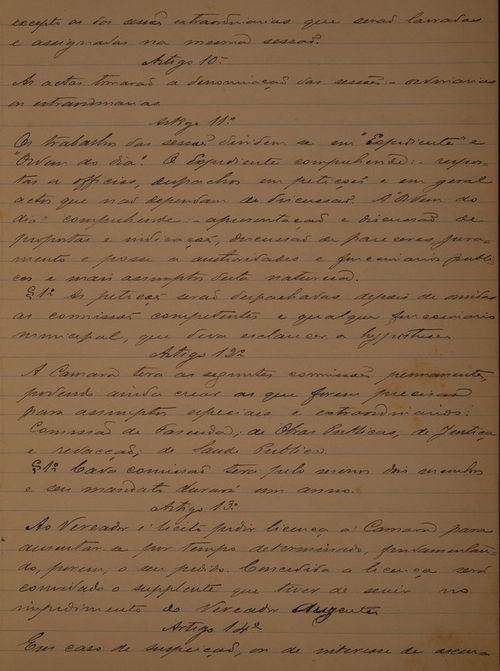
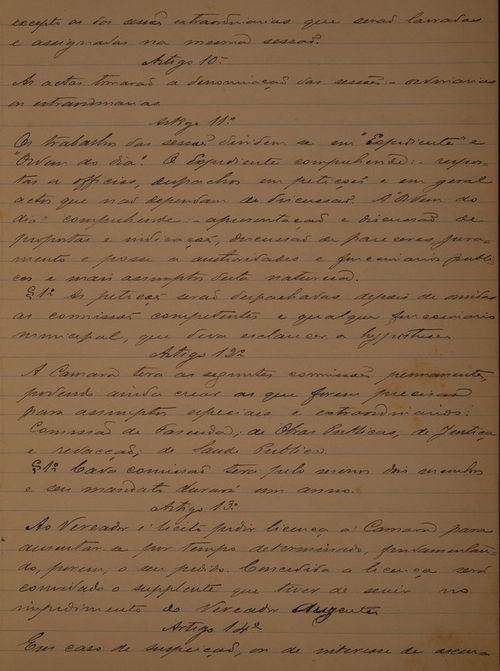
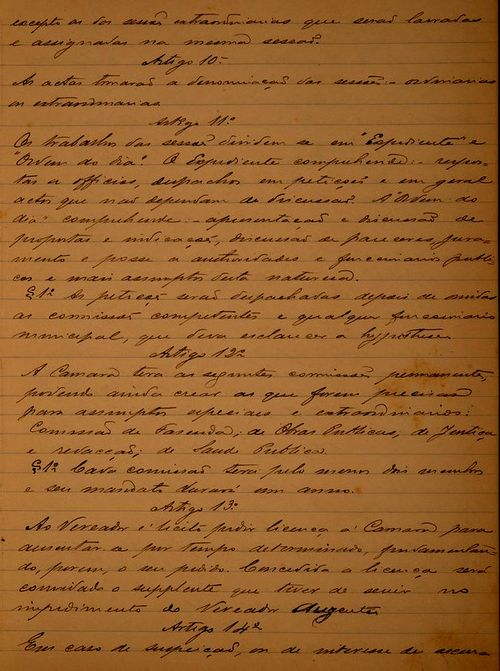
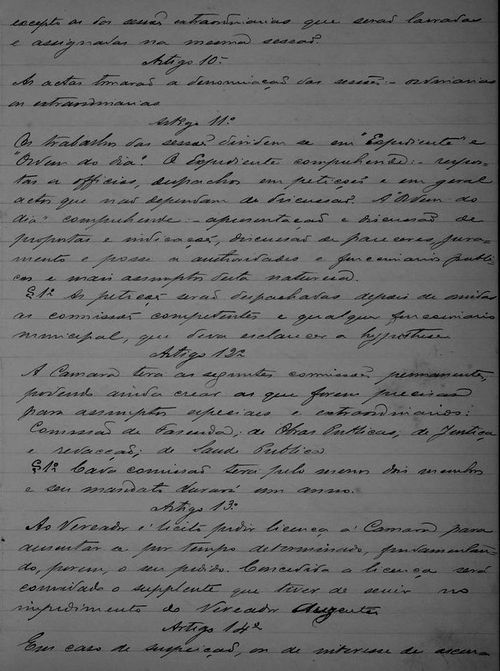
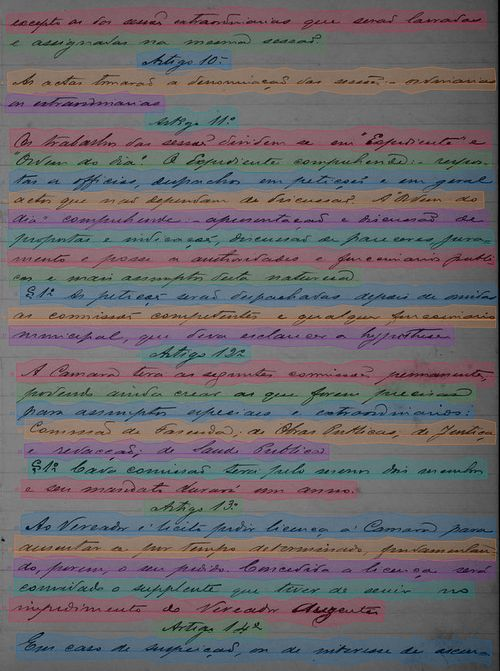
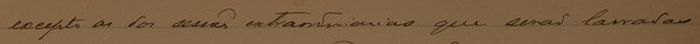
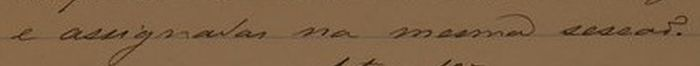
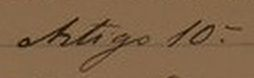
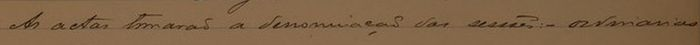
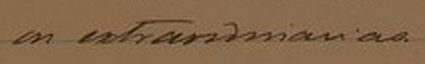
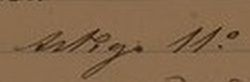
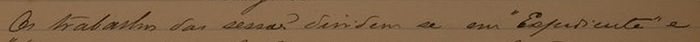
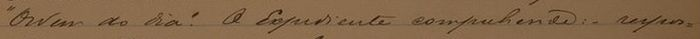
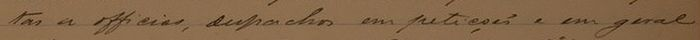
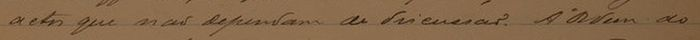
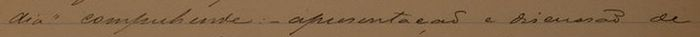
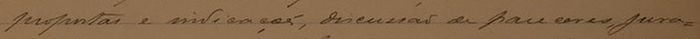
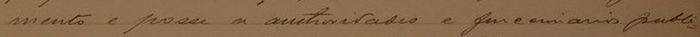
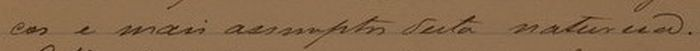
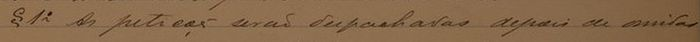
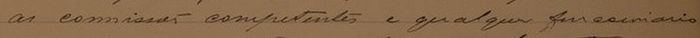
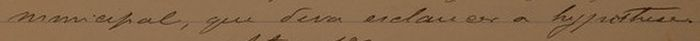
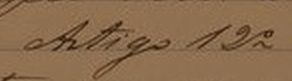
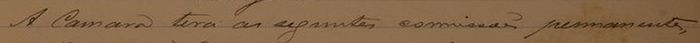
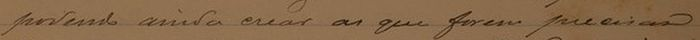
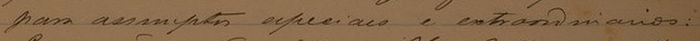
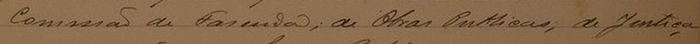
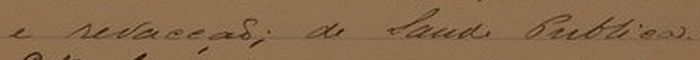
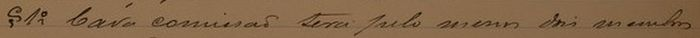
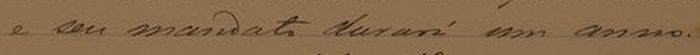
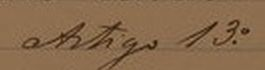
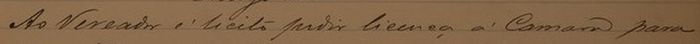
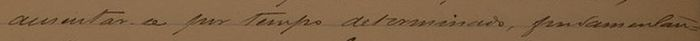
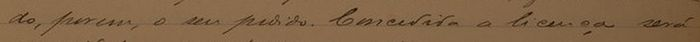
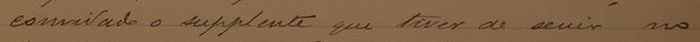
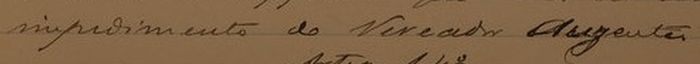
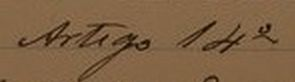
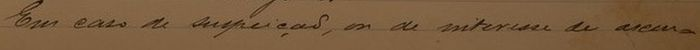

In [7]:
mostrar(9)

### Página 10 (reservada)


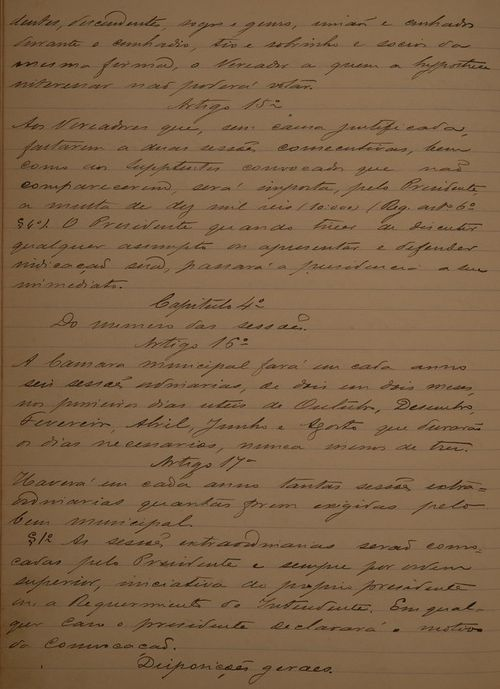
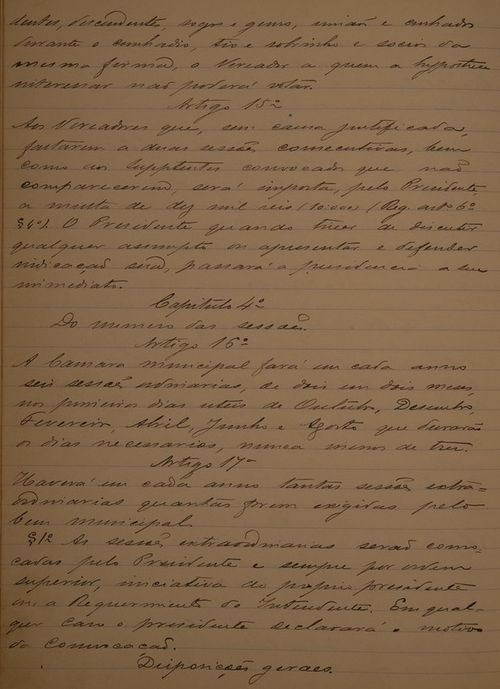
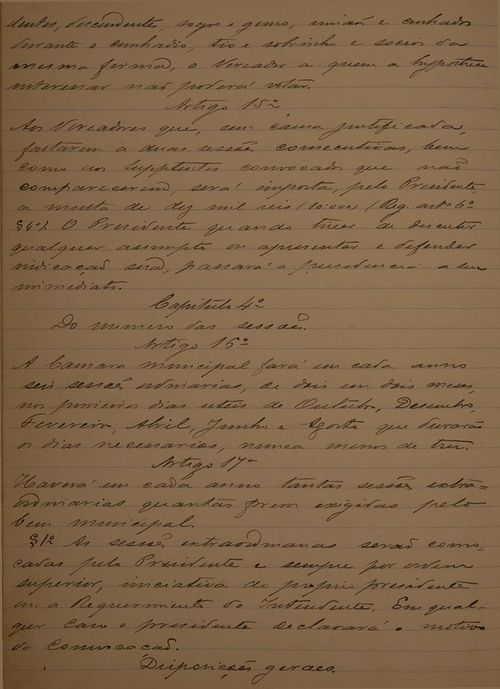
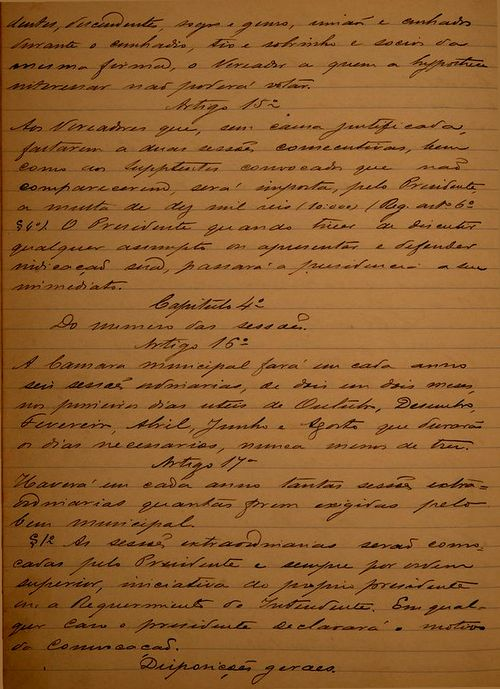
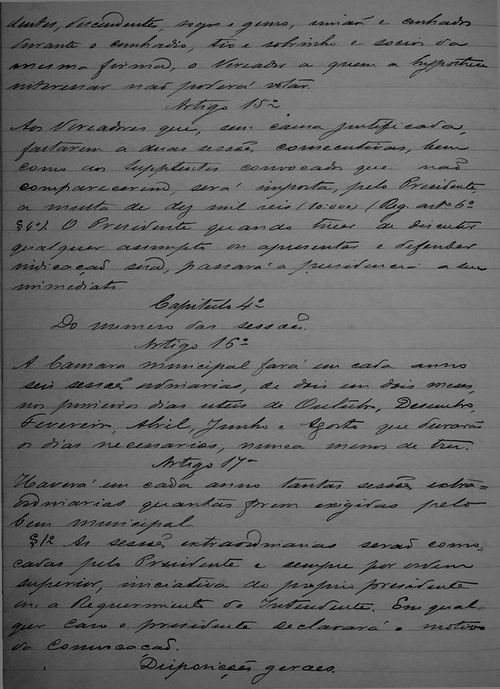
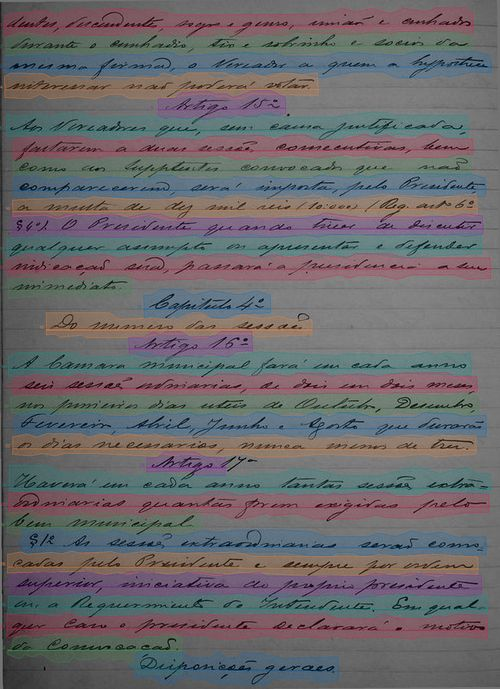
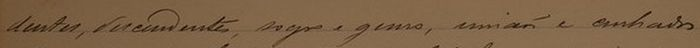
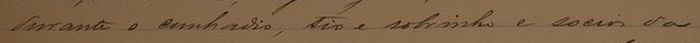
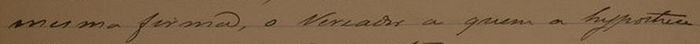
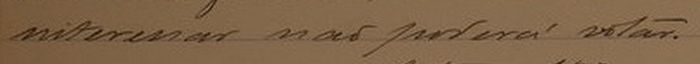
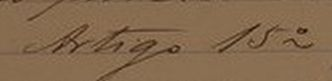
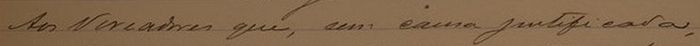
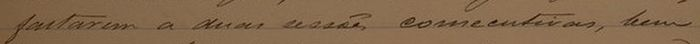
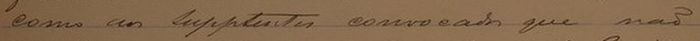
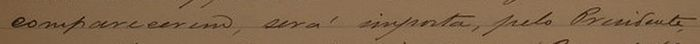
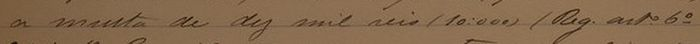
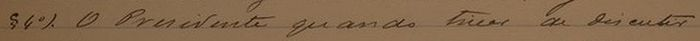
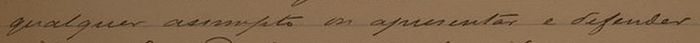
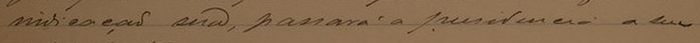
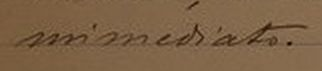
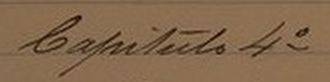
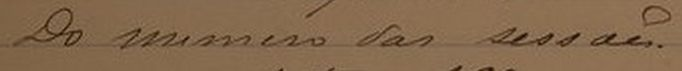
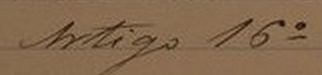
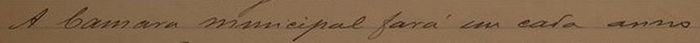
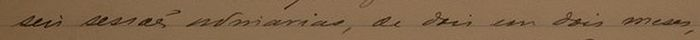
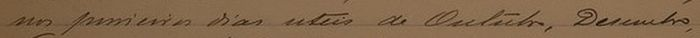
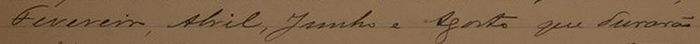
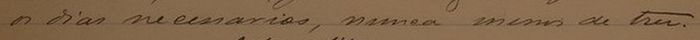
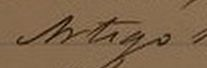
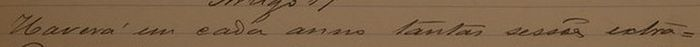
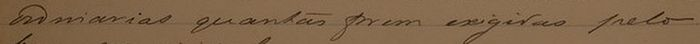
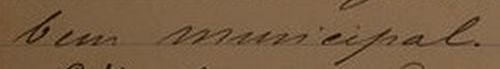
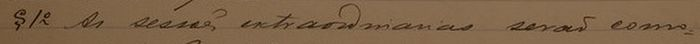
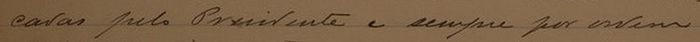
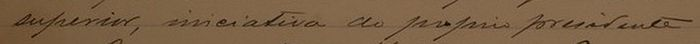
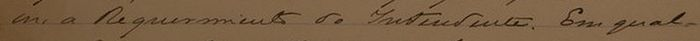
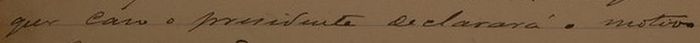
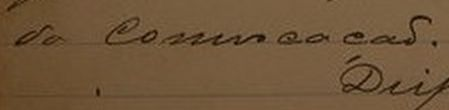
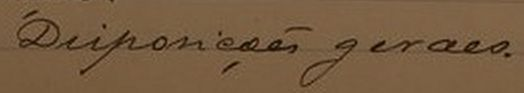

In [8]:
mostrar(10)

### Página 11 (ajuste)


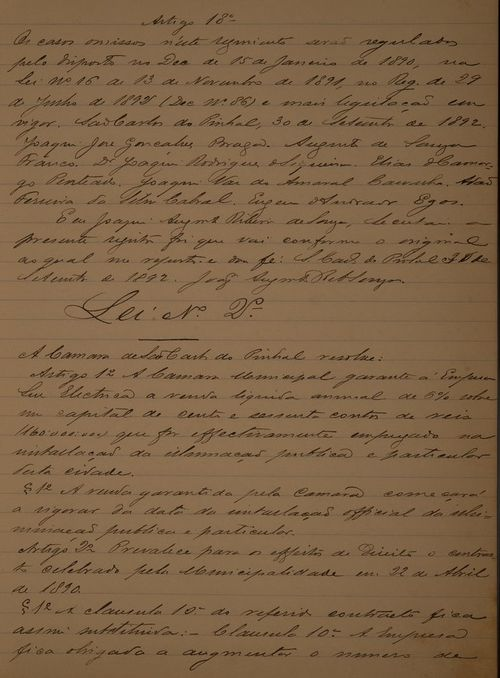
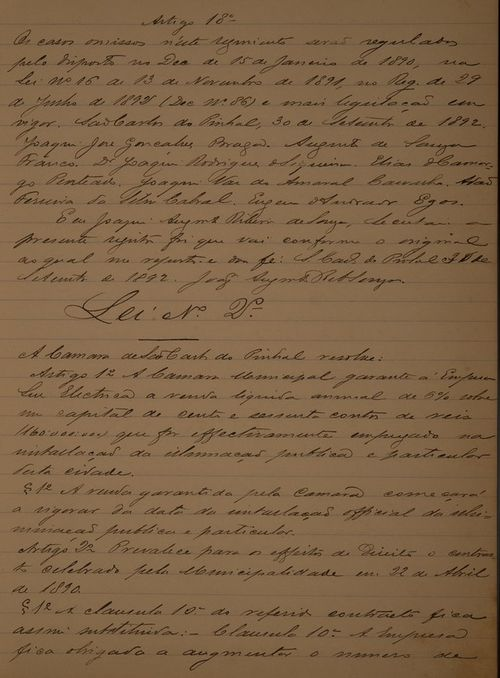
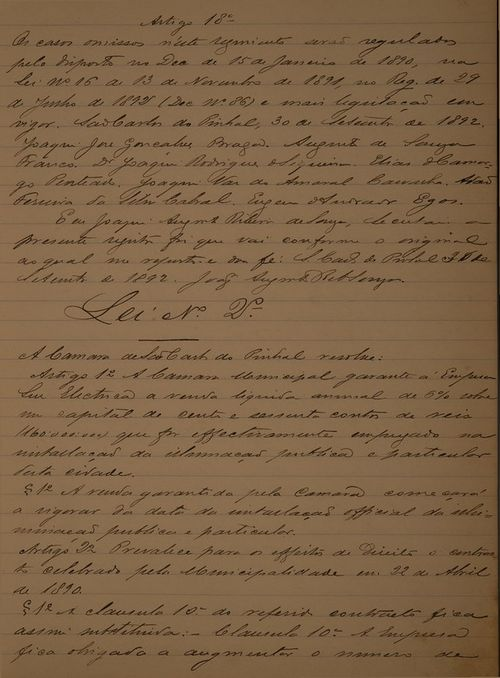
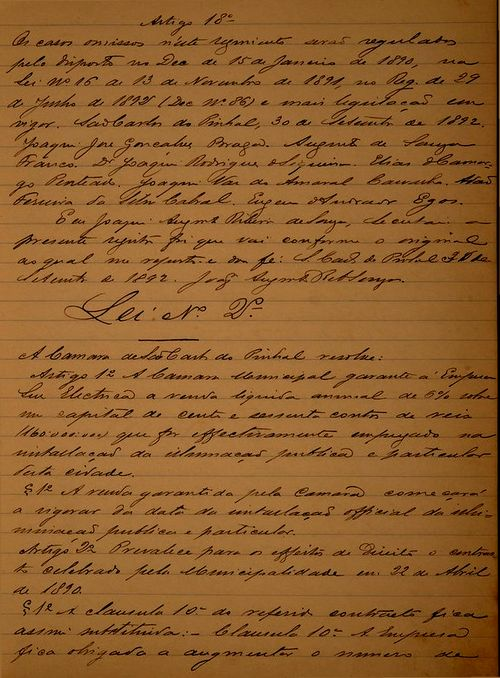
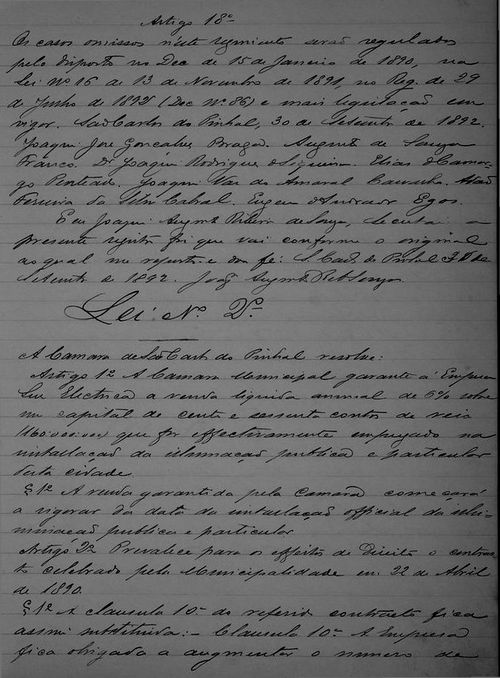
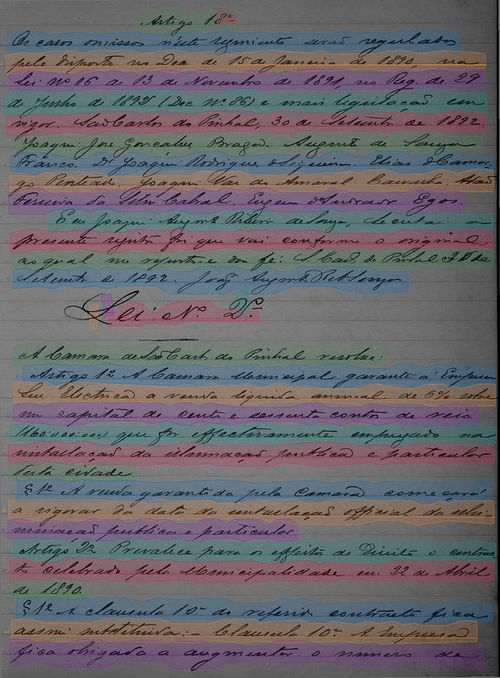
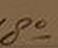
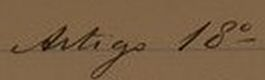
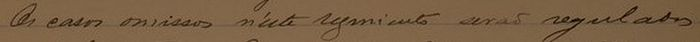
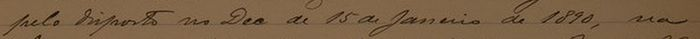
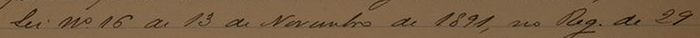
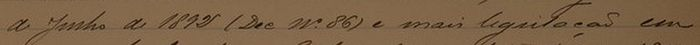
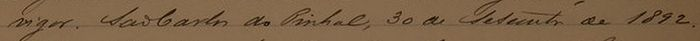
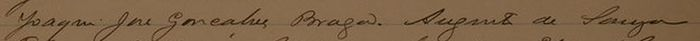
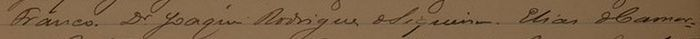
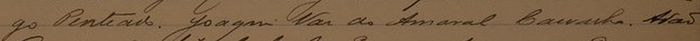
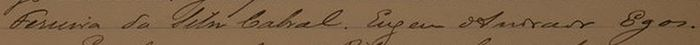
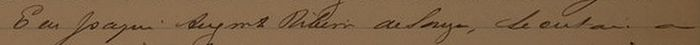
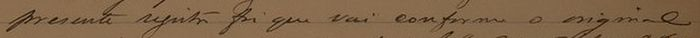
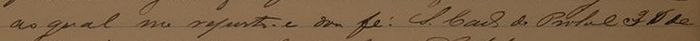
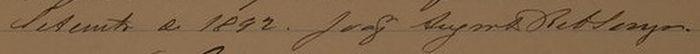
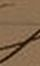
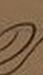
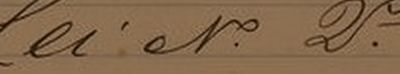
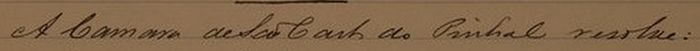
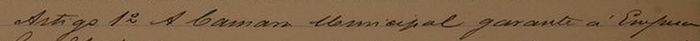
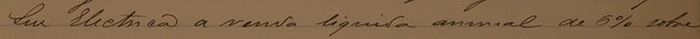
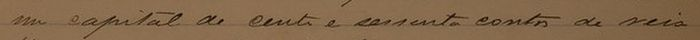
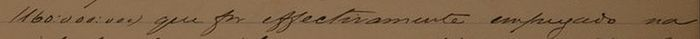
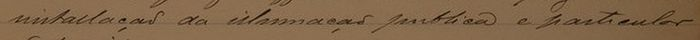
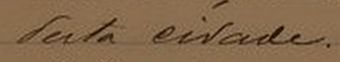
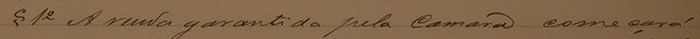
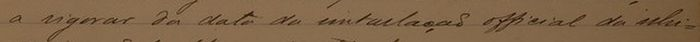
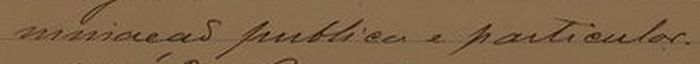
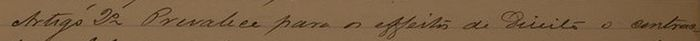
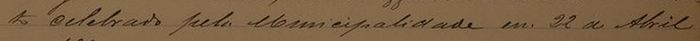
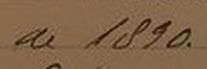
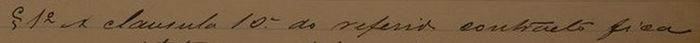
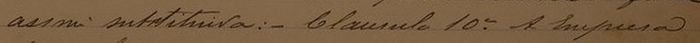
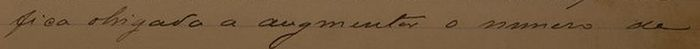

In [9]:
mostrar(11)

### Página 12 (reservada)


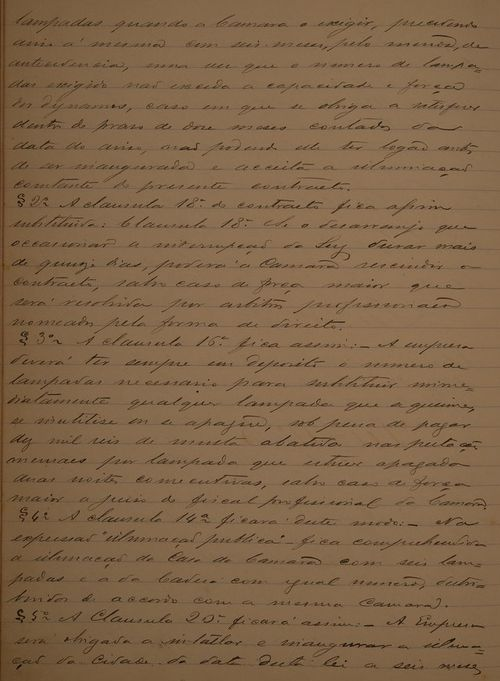
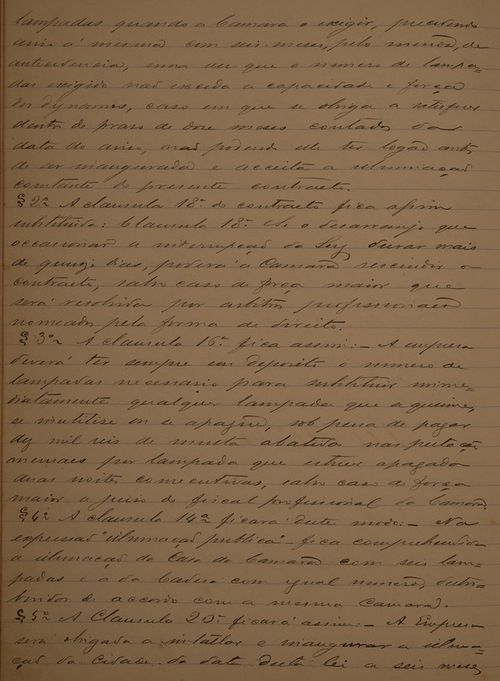
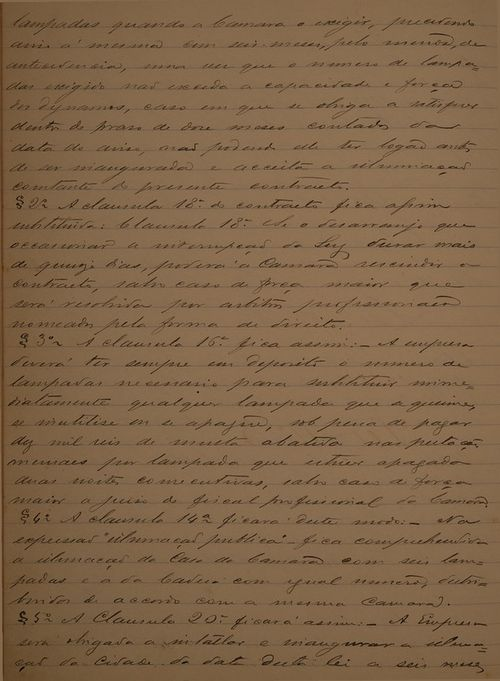
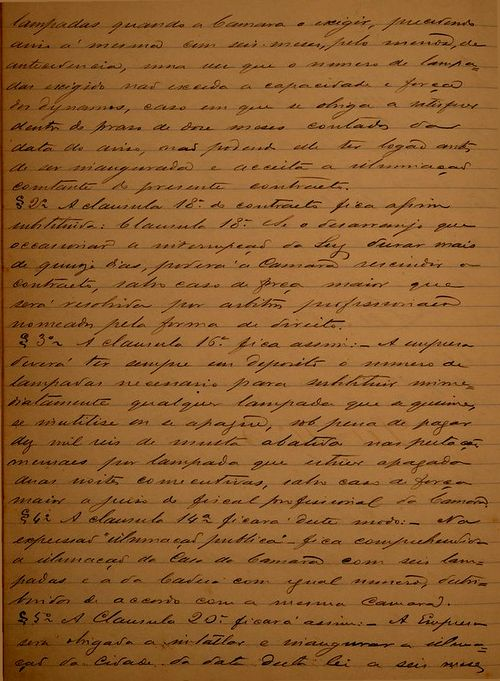
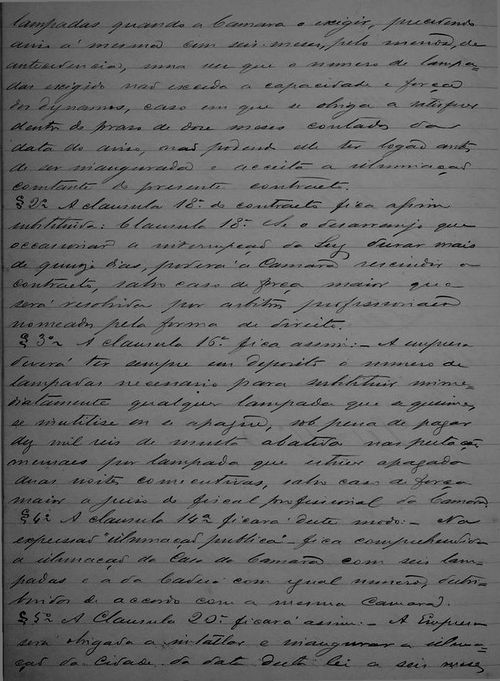
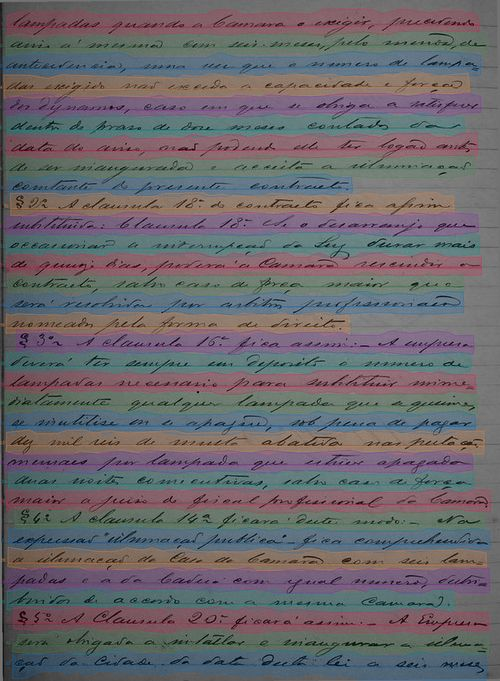
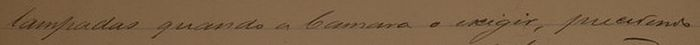
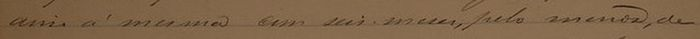
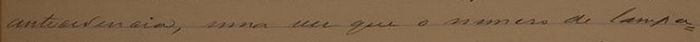
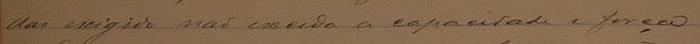
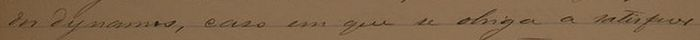
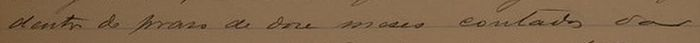
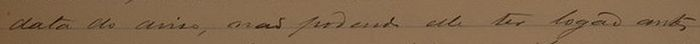
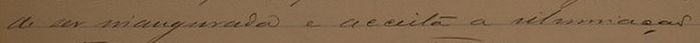
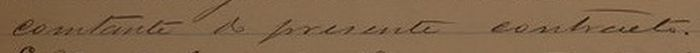
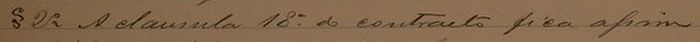
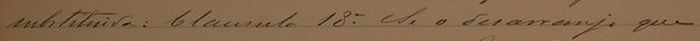
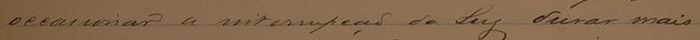
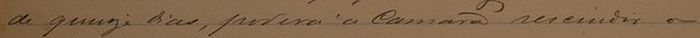
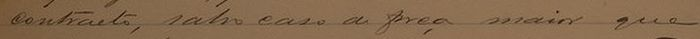
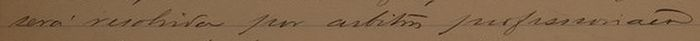
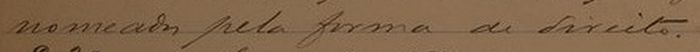
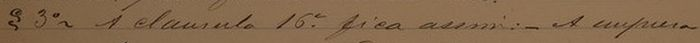
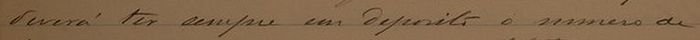
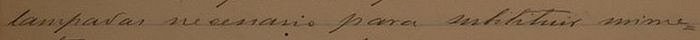
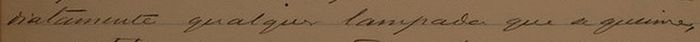
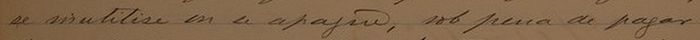
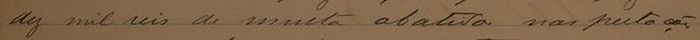
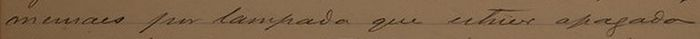
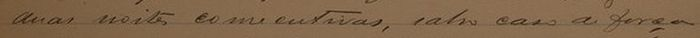
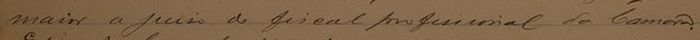
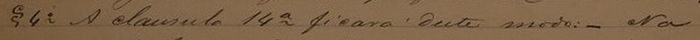
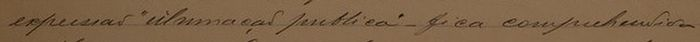
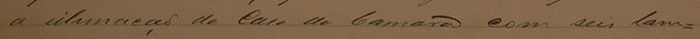
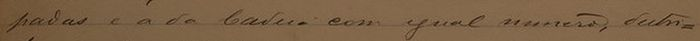
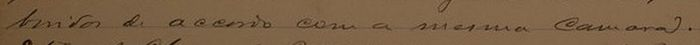
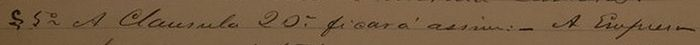
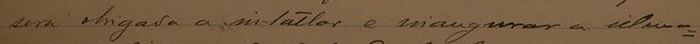
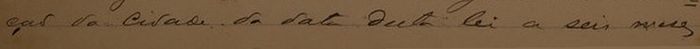

In [10]:
mostrar(12)

### Página 13 (ajuste)


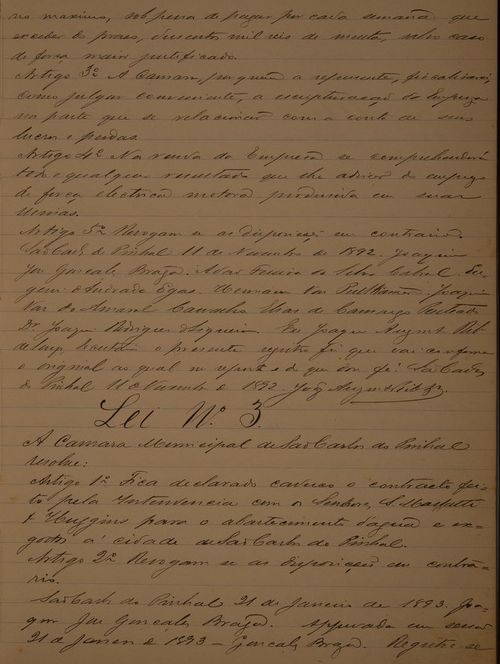
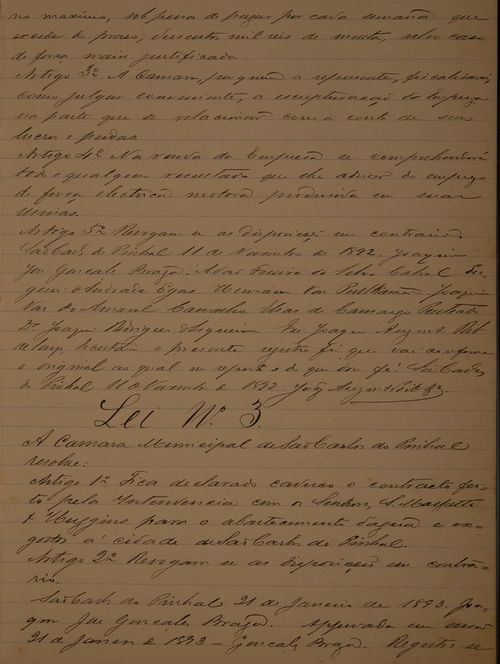
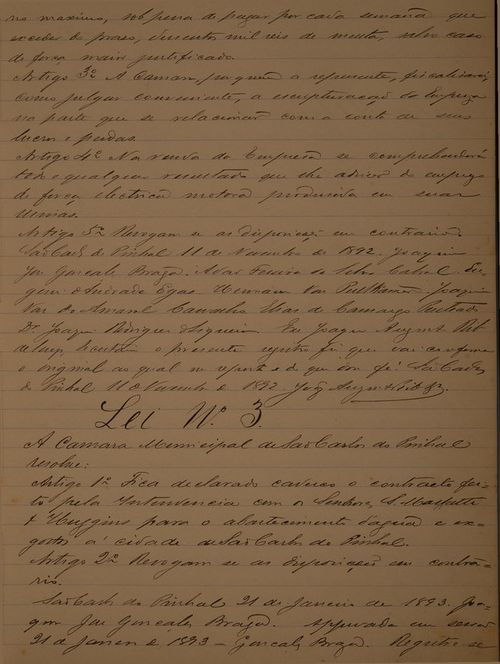
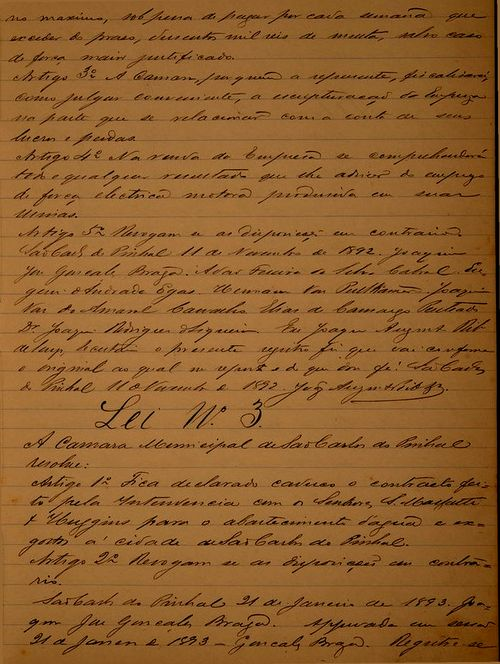
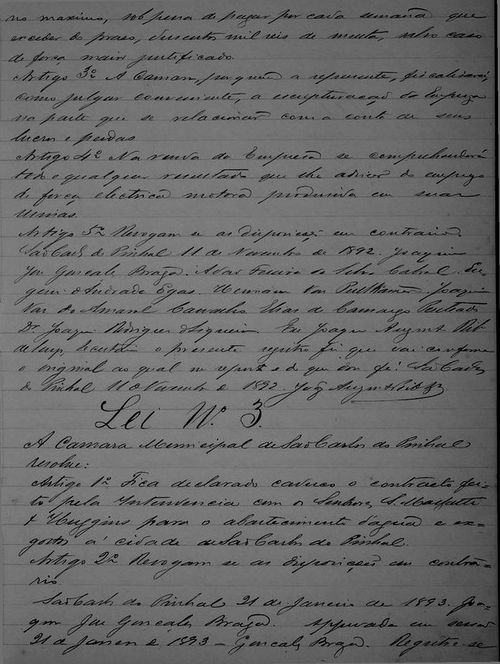
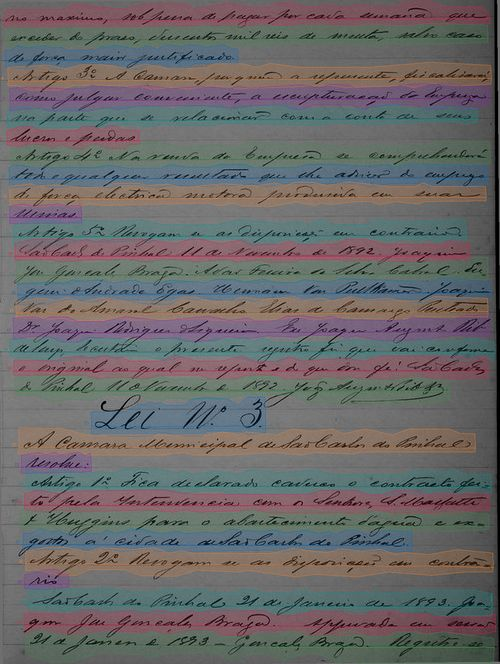
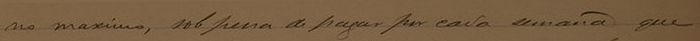
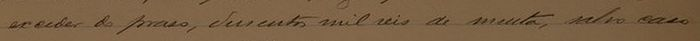
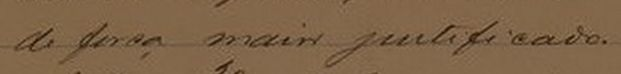
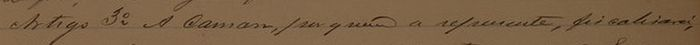
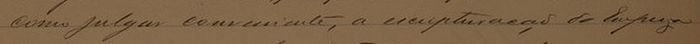
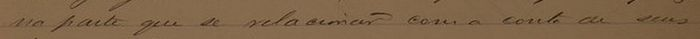
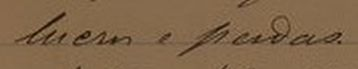
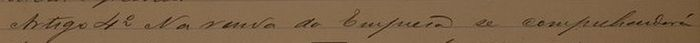
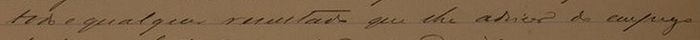
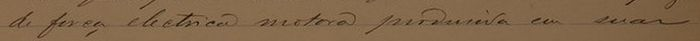
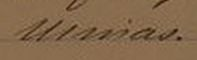
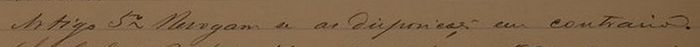
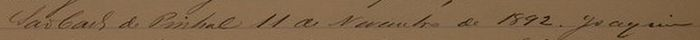
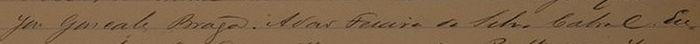
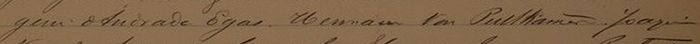
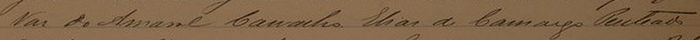
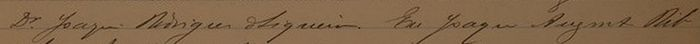
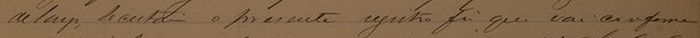
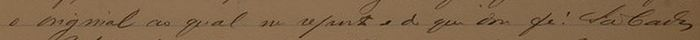
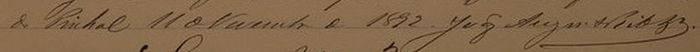
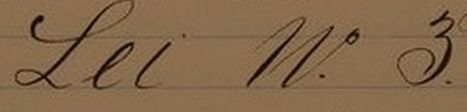
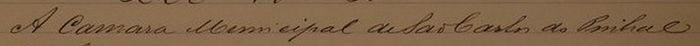
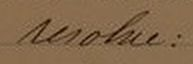
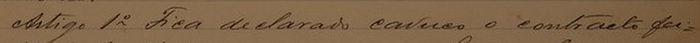
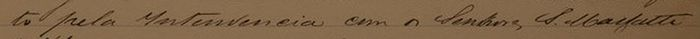
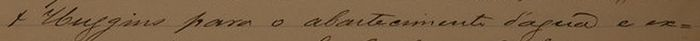
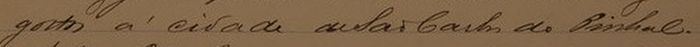
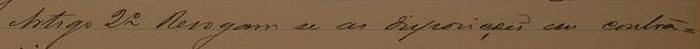
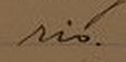
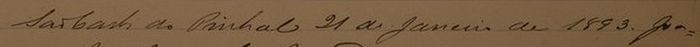
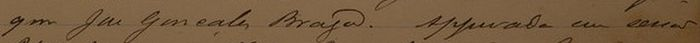
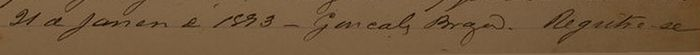

In [11]:
mostrar(13)

### Página 14 (ajuste)


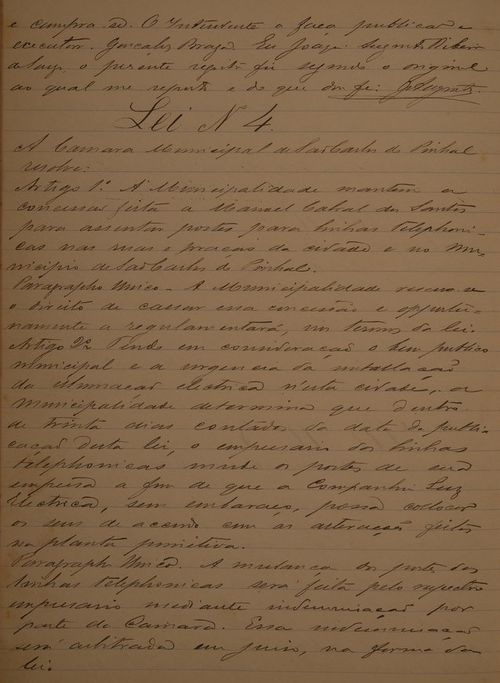
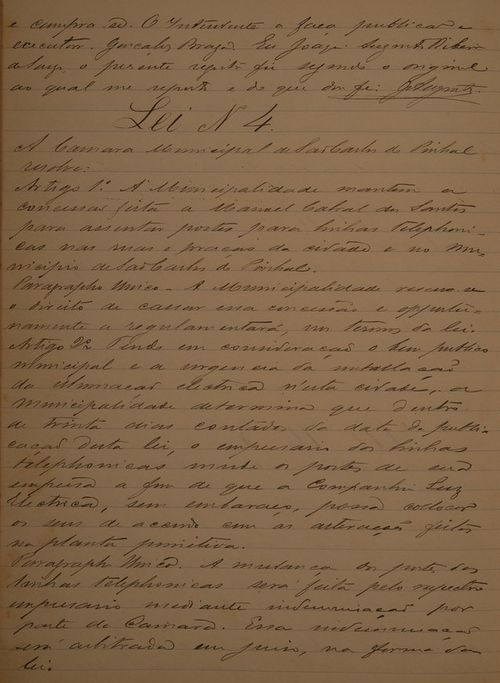
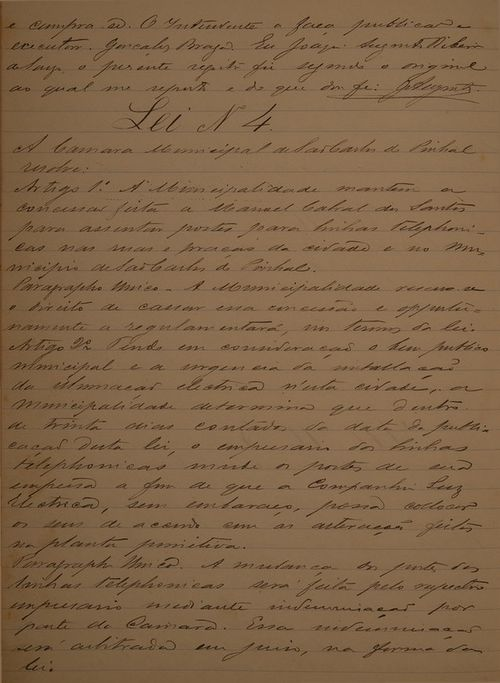
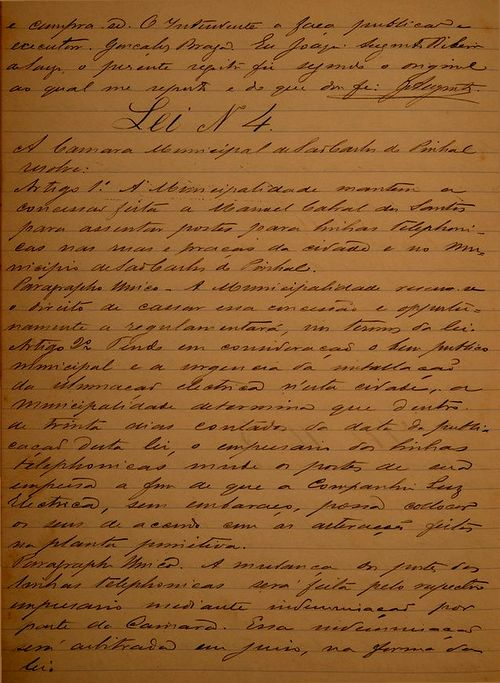
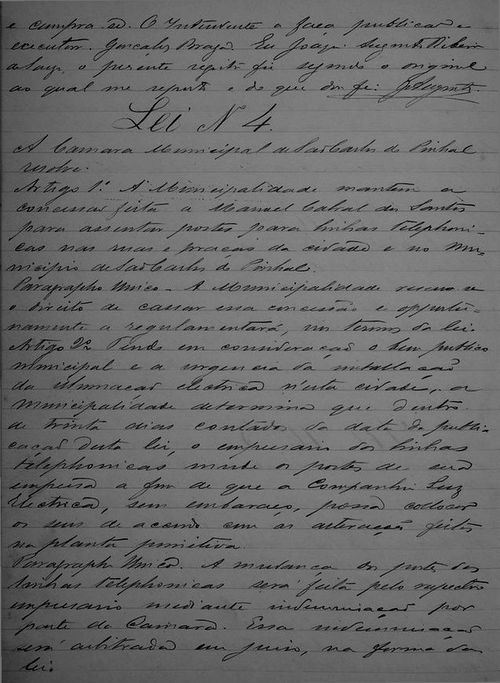
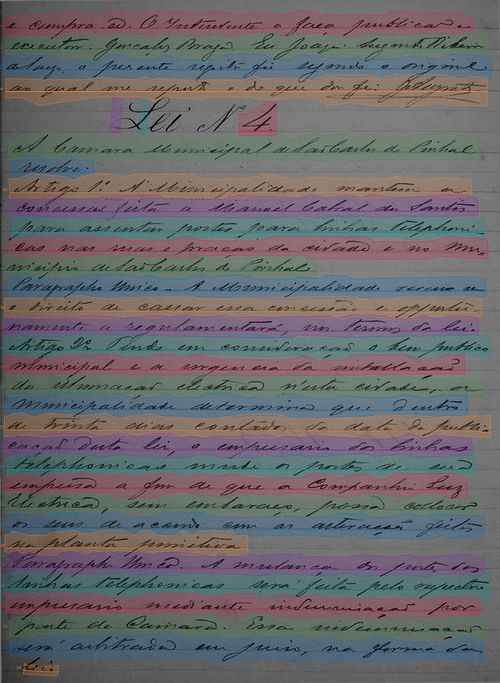
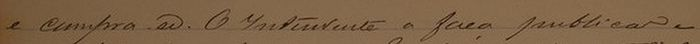
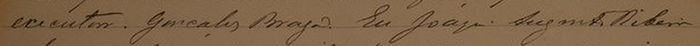
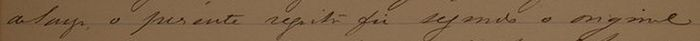
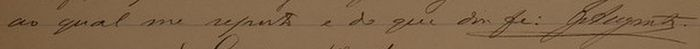
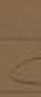
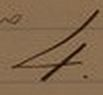
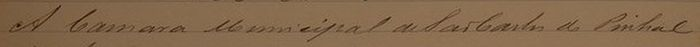
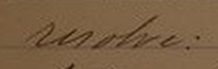
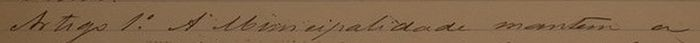
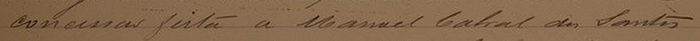
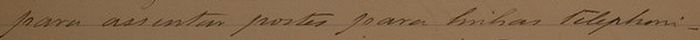
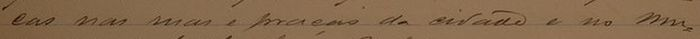
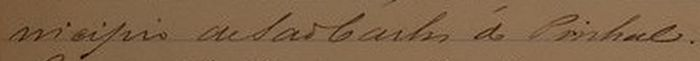
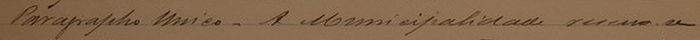
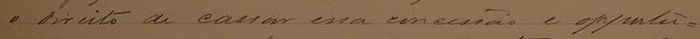
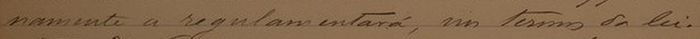
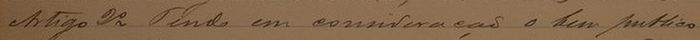
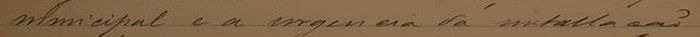
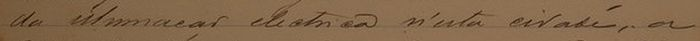
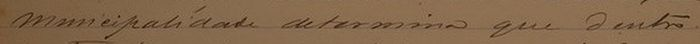
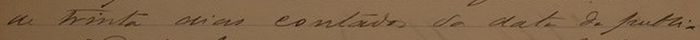
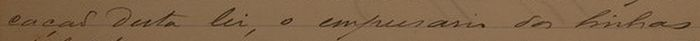
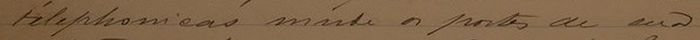
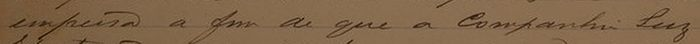
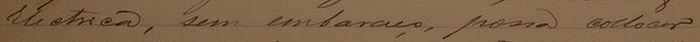
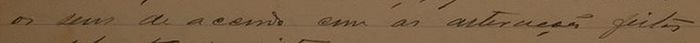
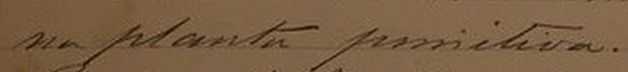
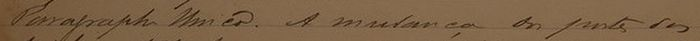
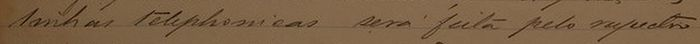
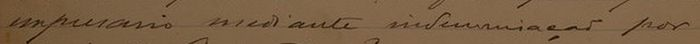
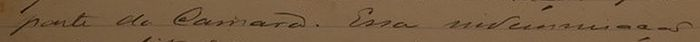
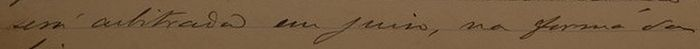
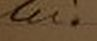

In [12]:
mostrar(14)

### Página 15 (ajuste)


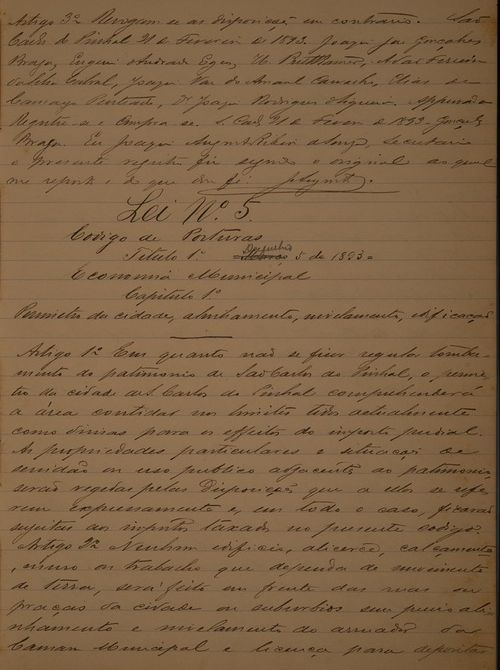
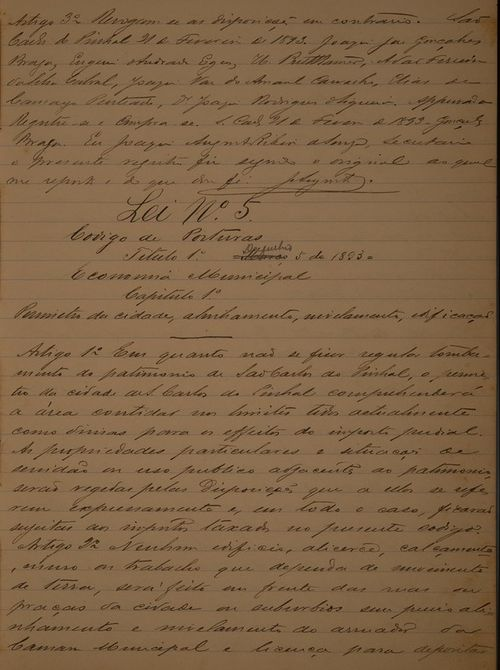
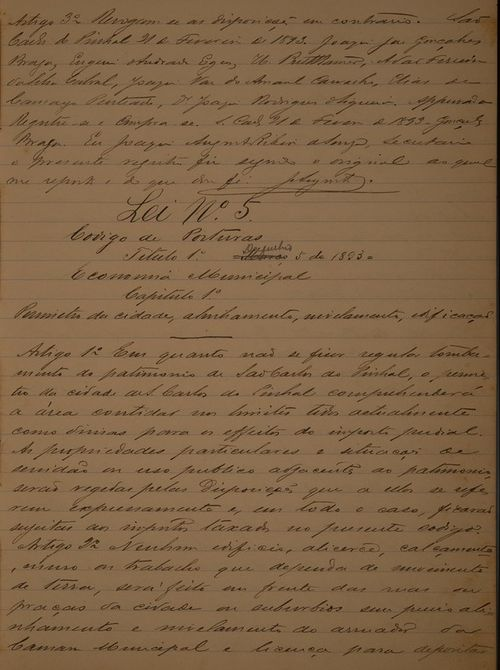
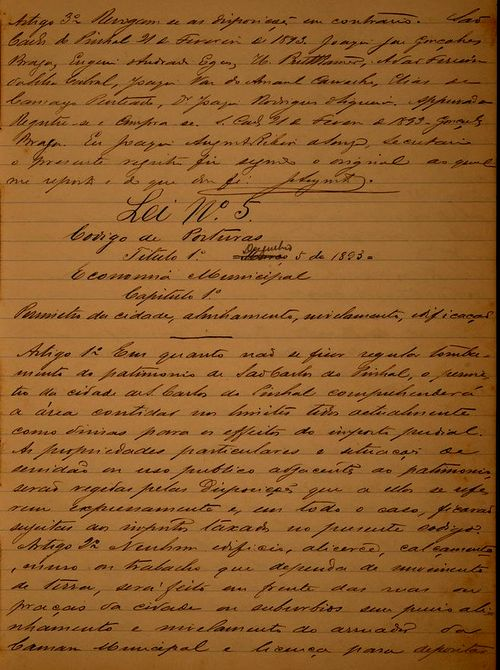
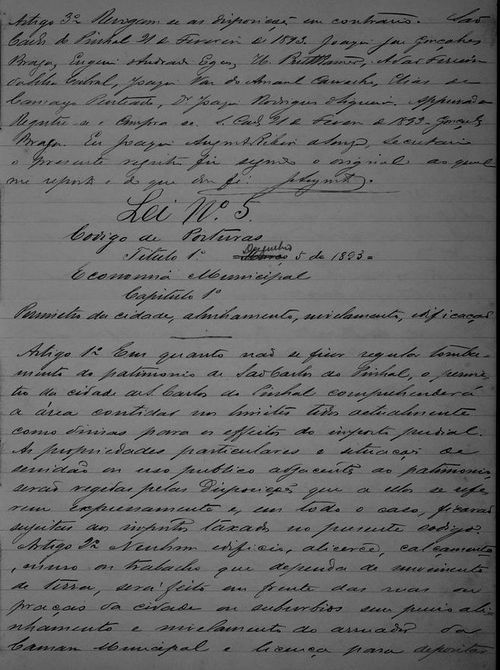
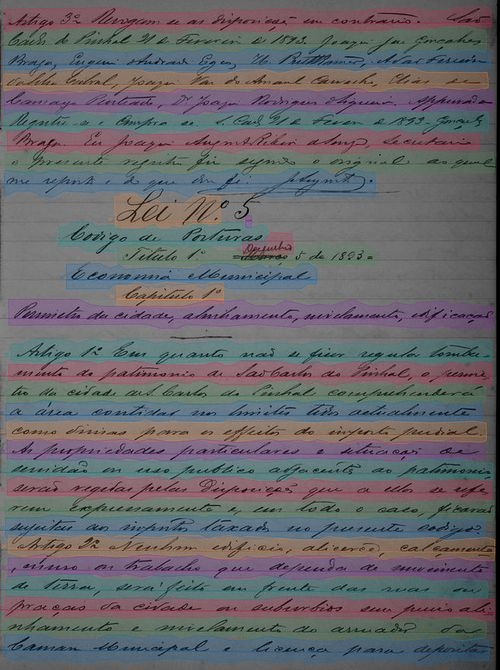
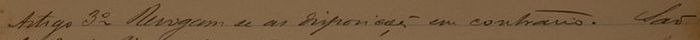
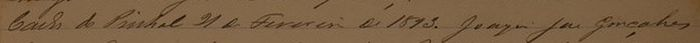
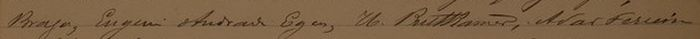
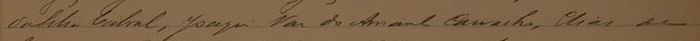
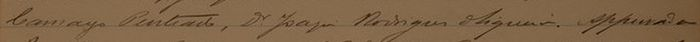
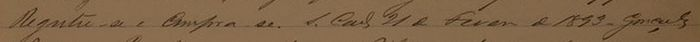
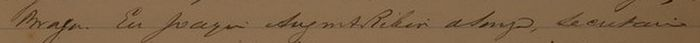
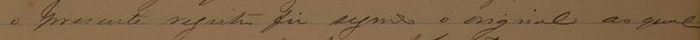
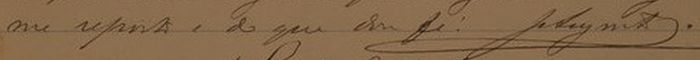
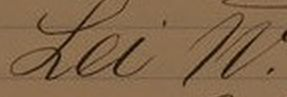
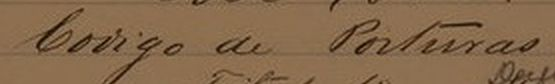
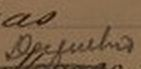
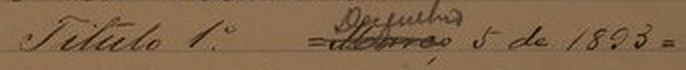
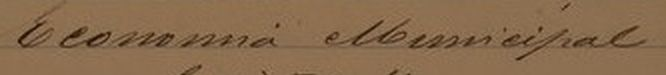
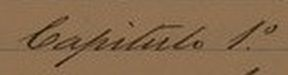
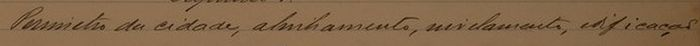
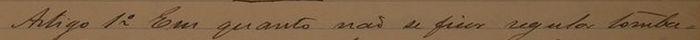
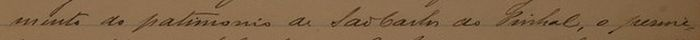
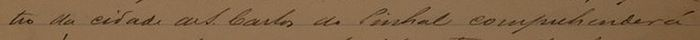
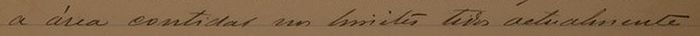
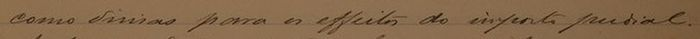
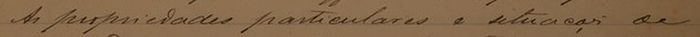
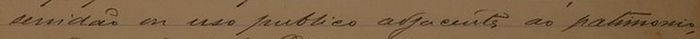
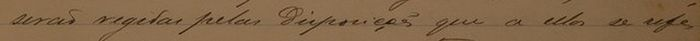
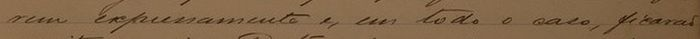
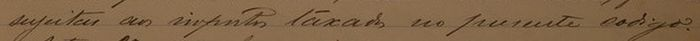
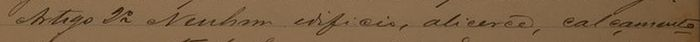
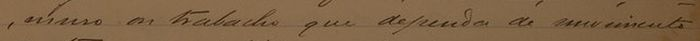
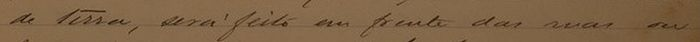
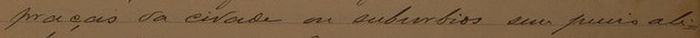
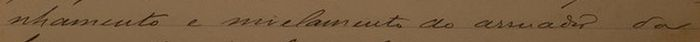
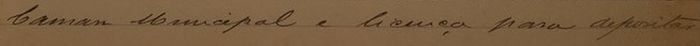

In [13]:
mostrar(15)

### Página 16 (ajuste)


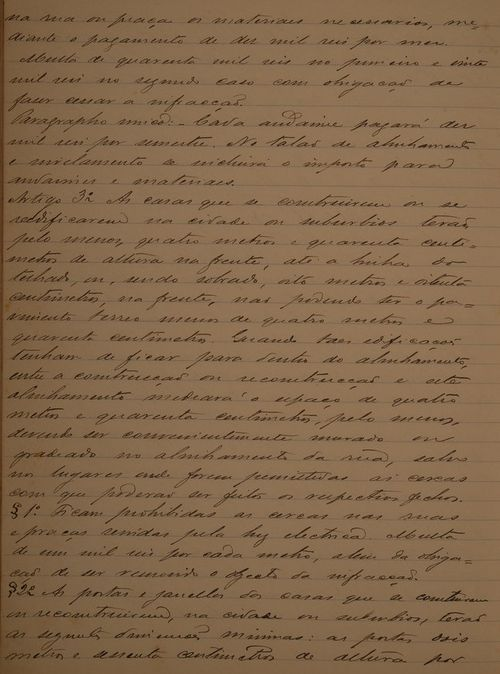
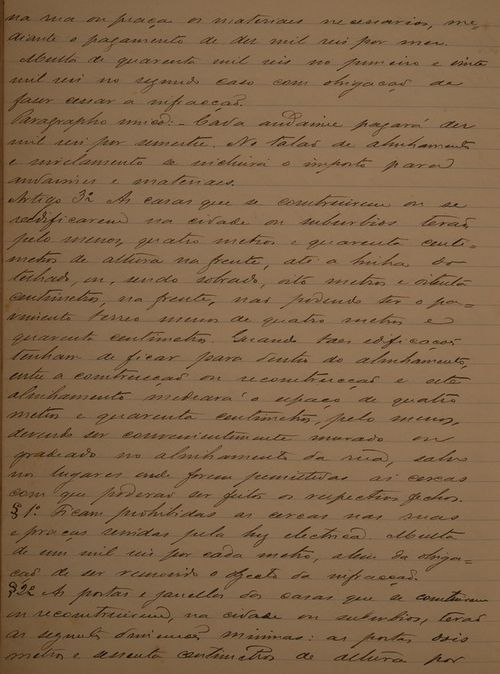
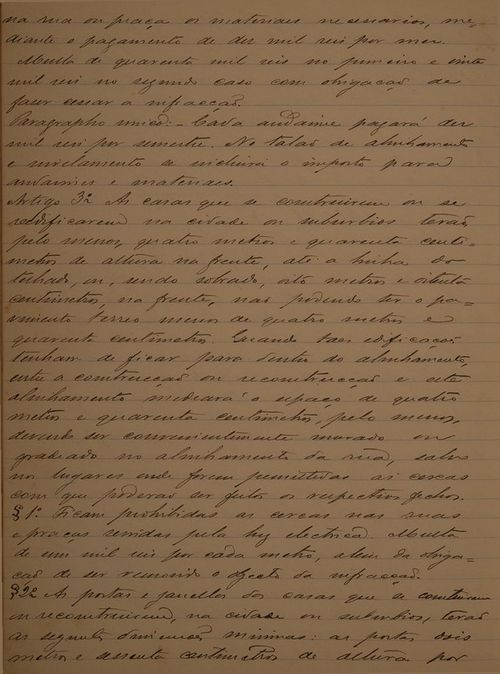
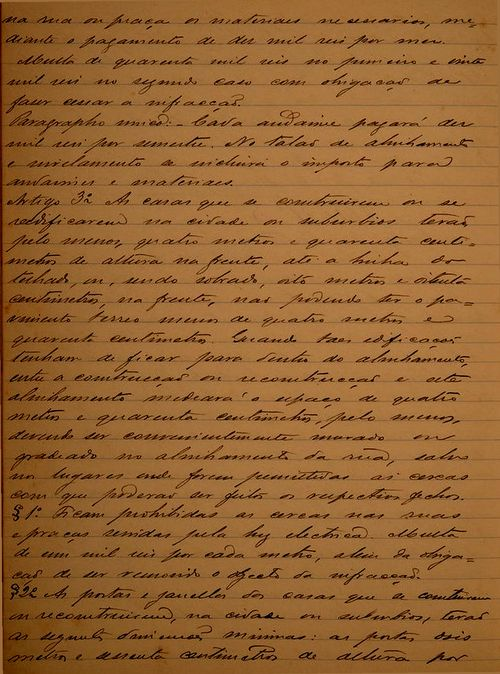
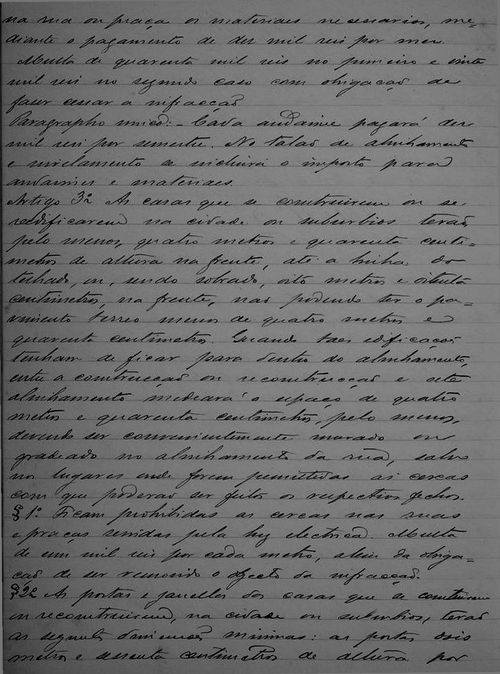
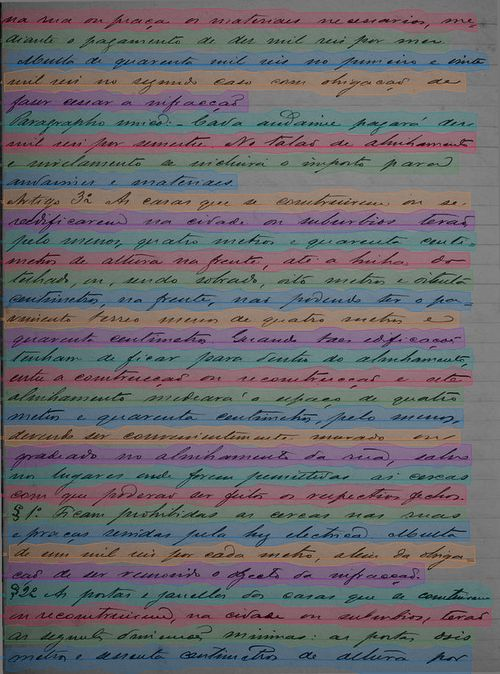
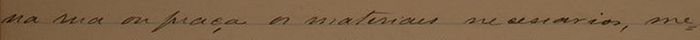
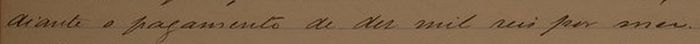
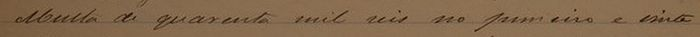
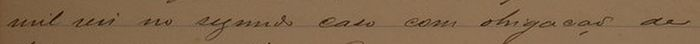
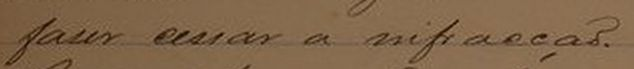
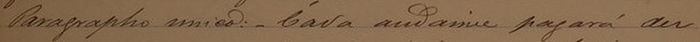
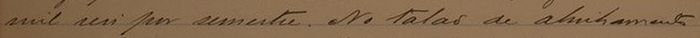
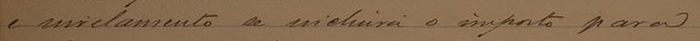
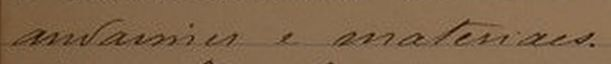
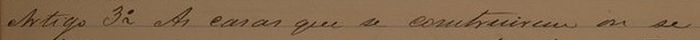
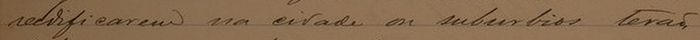
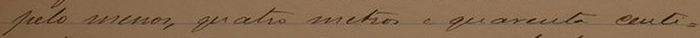
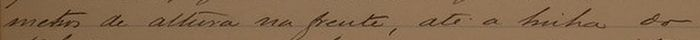
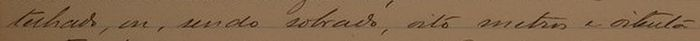
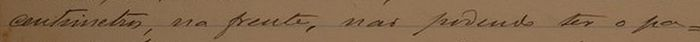
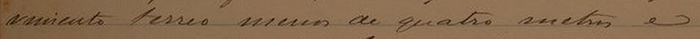
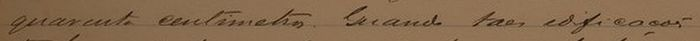
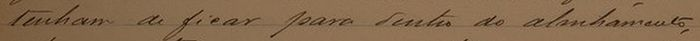
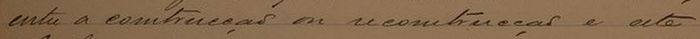
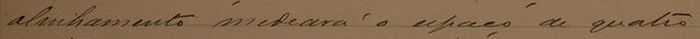
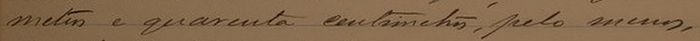
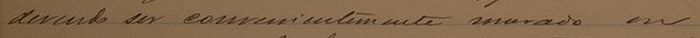
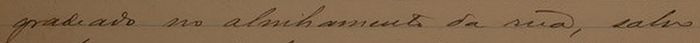
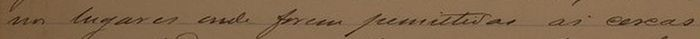
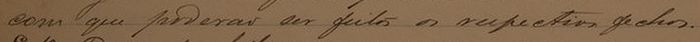
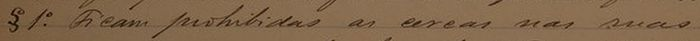
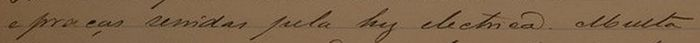
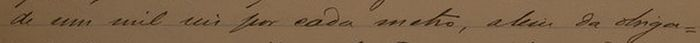
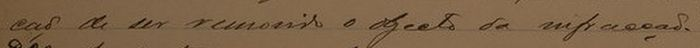
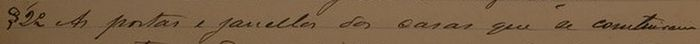
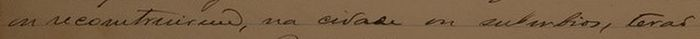
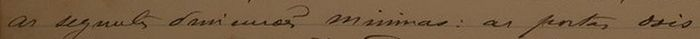
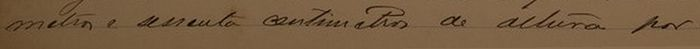

In [14]:
mostrar(16)

## Resumo das 12 páginas

WER normalizado final por página e do corpus. Os gráficos mostram o WER do corpus depois de cada etapa de texto, nas reservadas (estimativa honesta) e em todas as páginas.

In [15]:
mostrar_html('<h3>WER norm. final (%)</h3>' + summary_html(RESULTADOS, RESERVADAS_N))
for titulo, paginas in (('reservadas', sorted(RESERVADAS_N)), ('todas as páginas', sorted(RESULTADOS[NOME]))):
    etapas = stage_corpus(RESULTADOS[NOME], paginas)
    mostrar_html(f'<h3>WER norm. do corpus por etapa: {titulo} {paginas}</h3>'
                 + bar_svg({rotulo: 100 * s['wer_norm'] for rotulo, s in etapas}))

# textos finais em resultados/textos/pagina_NN.txt
pasta = Path('resultados/textos')
pasta.mkdir(parents=True, exist_ok=True)
for numero, etapas in RESULTADOS[NOME].items():
    (pasta / f'pagina_{numero:02d}.txt').write_text(etapas[-1].text, encoding='utf-8')
print('textos salvos em', pasta)

página,final
5 (ajuste),35.56
6 (ajuste),20.51
7 (reservada),19.07
8 (ajuste),14.88
9 (ajuste),20.40
10 (reservada),15.47
11 (ajuste),24.24
12 (reservada),20.08
13 (ajuste),25.75
14 (ajuste),16.08


textos salvos em resultados/textos
